# Практическая работа № 1. Открытые API, парсинг HTML (BeautifulSoup, XPath) и регулярные выражения

**Дисциплина:** «Анализ больших данных и рыночных тенденций»  
**Направление:** 38.04.05 «Бизнес-информатика», магистратура  
**Формат:** интерактивный ноутбук Google Colab · до 100 баллов · срок сдачи — по графику курса

## Цель работы

Научиться самостоятельно добывать рыночные данные там, где нет готового датасета: забирать их из открытых API, извлекать из HTML-страниц, приводить «грязный» текст к числам и датам и превращать результат в управленческие выводы.

## Задачи

1. Спроектировать вежливый сбор данных через REST API: параметры, пагинация, заголовки, паузы, повторные попытки, обработка ошибок.
2. Извлечь данные из статических HTML-страниц двумя независимыми способами — CSS-селекторами BeautifulSoup и выражениями XPath — и сверить результаты.
3. Нормализовать «грязные» поля (цены, остатки, зарплатные вилки, даты, технологии в тексте требований) регулярными выражениями.
4. Собрать единый `pandas.DataFrame`, провести разведочный анализ и построить корректные графики.
5. Сформулировать выводы и рекомендации для лица, принимающего решение, с опорой на посчитанные метрики.

## Стек

| Слой | Инструменты |
|---|---|
| Сбор | `requests` (+ `urllib3.Retry`), открытые REST API, кэш ответов на диске |
| Разбор HTML | `BeautifulSoup4` (CSS-селекторы), `lxml` (XPath) |
| Очистка | `re` — регулярные выражения |
| Анализ и графики | `pandas`, `numpy`, `matplotlib`, `seaborn` |
| Среда | Google Colab (работает и в локальном Jupyter) |

## Что сдаётся

Выполненный ноутбук **со всеми выводами ячеек**, загруженный в личный публичный репозиторий GitHub; в LMS сдаётся **ссылка на репозиторий**. Файлы и архивы не принимаются. Ключи, токены и пароли в ноутбуке недопустимы — за это снимаются баллы (см. раздел «Штрафы»).

## Как работать с этим ноутбуком

1. **Файл → Сохранить копию на Диске.** Работайте только в своей копии.
2. В ячейке «Шаг 1» задайте **номер варианта** (выдаёт преподаватель), свой контактный e-mail и паузу между запросами. Параметры варианта подставятся автоматически.
3. Выполняйте ячейки **строго сверху вниз**. Перед каждым блоком кода есть пояснение «Зачем мы это делаем», после — «Как читать полученный вывод».
4. Места, которые нужно дописать, помечены `TODO`. Пока шаг не выполнен, ячейка честно падает с `NotImplementedError` — это нормально.
5. Перед сдачей запустите ячейку **самопроверки**: она должна показать «Выполнено: 11 из 11».

### Три правила вежливого сбора данных

* **Пауза между запросами.** `REQUEST_PAUSE = 0.5` секунды — нижняя граница для учебной работы. Сервер, который вы «положите», принадлежит другим людям.
* **Кэш включён по умолчанию.** Повторный запуск ячейки берёт ответ с диска, а не из сети: это и быстрее, и вежливее. Чтобы получить свежие данные, выключите `USE_CACHE` или очистите папку кэша.
* **Никаких ключей в коде.** Токены читаются функцией `get_secret()` из Colab Secrets (значок ключа слева) или переменных окружения.

### Если источник недоступен

Интернет в Colab иногда блокирует отдельные домены, а сайты меняют вёрстку. В ноутбуке предусмотрены аварийные режимы (синтетические данные и офлайн-снимок разметки): пайплайн доработает до конца, но в выводе появится предупреждение. **Выводы по аварийным данным не принимаются** — повторите сбор, когда источник снова доступен.

## Мини-теория 1. REST API: как устроен этичный сбор

**API** — это контракт: вы отправляете HTTP-запрос по определённому адресу и получаете структурированный ответ (почти всегда JSON). В отличие от парсинга HTML, здесь данные уже разобраны по полям, а правила использования описаны явно.

### Анатомия запроса

```
GET https://api.github.com/search/repositories ? q=web+scraping & sort=stars & per_page=50 & page=2
    └──────── эндпоинт ────────────────────────┘ └──────────── параметры запроса ───────────────┘
Заголовки: User-Agent: MGPU-BI-PW1/1.0 (contact: student@mgpu.ru)
           Authorization: Bearer <токен>        ← если сервис требует авторизацию
```

* **Эндпоинт** — «ручка» сервиса: `/vacancies`, `/works`, `/search/repositories`.
* **Параметры** уточняют выборку: поисковая строка, фильтры, сортировка, размер страницы.
* **Заголовки** описывают клиента. `User-Agent` с контактом — правило хорошего тона: по нему администратор сервиса сможет с вами связаться, а не просто заблокировать.
* **Коды ответа** — первое, что нужно проверять:

| Код | Что значит | Что делать |
|---|---|---|
| 200 | всё хорошо | разбирать `r.json()` |
| 301 / 302 | адрес изменился | проверить итоговый `r.url` |
| 400 | неверные параметры | сверить имена и типы параметров с документацией |
| 401 / 403 | нет доступа или ключа | получить ключ, проверить заголовки; иногда сервис закрыл публичный доступ |
| 404 | объекта нет | проверить путь и идентификатор |
| 429 | превышен лимит | подождать `Retry-After`, увеличить паузу |
| 5xx | сбой на стороне сервиса | повторить с экспоненциальной задержкой |

### Пагинация

Сервисы отдают данные страницами. Три частых схемы:

| Схема | Параметры | Примеры |
|---|---|---|
| Номер страницы | `page`, `per_page` | GitHub, OpenAlex |
| Смещение и размер | `offset`, `limit` | «Работа в России» |
| Курсор | `cursor`, `next` | сервисы с большим объёмом |

Правило остановки: страница вернула меньше записей, чем `per_page`, — данные закончились. Бесконечный `while True` без такой проверки — классическая ошибка, которая либо зациклится, либо упрётся в лимит.

### Ограничение частоты (rate limiting)

Сервис считает ваши запросы и при превышении отвечает 429. Практика:

* пауза между запросами (`time.sleep`);
* повторные попытки с **экспоненциальной задержкой** — в работе это `urllib3.Retry(backoff_factor=1.5)`: 1,5 с → 3 с → 6 с;
* уважение заголовков `X-RateLimit-Remaining` и `Retry-After`;
* кэширование ответов, чтобы при отладке не ходить в сеть повторно.

### Ключи и секреты

Многие API требуют ключ. Хранить его в коде нельзя: ноутбук уедет в репозиторий вместе с ключом, и ключ придётся отзывать. В Colab есть **Secrets** (значок ключа на панели слева): значение хранится в аккаунте, а код получает его через `userdata.get("MY_KEY")`. В работе это обёрнуто в `get_secret()`.

### Что изменилось к 2026 году (важно для выбора источника)

* **hh.ru**: с апреля 2026 публичный метод `GET /vacancies` отвечает `403 Forbidden` на неавторизованные запросы; ключ выдают в основном работодателям и рекрутинговым сервисам через модерацию приложения. Старые учебные примеры с hh.ru больше не воспроизводятся. Российская открытая альтернатива — портал **«Работа в России»** (`opendata.trudvsem.ru`), данные Роструда, ключ не нужен.
* **OpenAlex**: с 13 февраля 2026 всем запросам нужен бесплатный `api_key`, параметр `mailto` и «polite pool» отменены. Действует бесплатный лимит около $1 в сутки; запросы `search` дороже, чем `filter`, а получение объекта по идентификатору бесплатно. Отсюда практический приём: `per-page=100` и фильтры вместо поиска.
* **GitHub**: без токена — 60 запросов в час на IP, с персональным токеном — 5000 в час; у поиска отдельный лимит (10 и 30 запросов в минуту соответственно).

Вывод для аналитика: **источник — это не константа**. Перед сбором проверяйте документацию и код ответа, а в отчёте фиксируйте дату сбора.

## Мини-теория 2. HTML, DOM и селекторы: BeautifulSoup против XPath

Когда API нет, данные забирают из HTML. Браузер превращает разметку в **DOM** — дерево элементов:

```
html
└── body
    └── article.product_pod                 ← карточка товара
        ├── h3 > a[title="Sharp Objects"]   ← название лежит в АТРИБУТЕ, а не в тексте
        ├── p.star-rating.Three             ← рейтинг закодирован КЛАССОМ
        └── div.product_price
            ├── p.price_color   → "£47.82"
            └── p.instock.availability → "In stock (22 available)"
```

Задача парсера — описать путь к нужному узлу так, чтобы он пережил мелкие изменения вёрстки.

### Два инструмента

| | BeautifulSoup + CSS | lxml + XPath |
|---|---|---|
| Синтаксис | `soup.select("article.product_pod p.price_color")` | `tree.xpath('//article[contains(@class,"product_pod")]//p[@class="price_color"]/text()')` |
| Читаемость | выше, привычно по вёрстке | ниже, но выражения мощнее |
| Атрибут | `el.get("title")` | `.../@title` |
| Текст | `el.get_text(" ", strip=True)` | `.../text()` |
| Поиск по тексту | `soup.find("th", string="UPC")` | `//th[text()="UPC"]` |
| Движение «вверх» и «вбок» | `el.parent`, `el.find_next_sibling()` | оси: `parent::`, `following-sibling::`, `ancestor::` |
| Условие по числу | средствами Python | `[position() <= 3]`, `[last()]` |
| Скорость | ниже (чистый Python поверх парсера) | выше (C-библиотека) |

**Когда что удобнее.** CSS-селекторы — для «плоских» повторяющихся карточек. XPath — когда нужно зацепиться за текст-подпись и взять соседнюю ячейку: классика — таблица характеристик товара:

```python
# «Найти ячейку th со словом UPC и взять следующий за ней td»
tree.xpath('//th[text()="UPC"]/following-sibling::td[1]/text()')
```

### Практические правила

1. **Цепляйтесь за смысл, а не за форму.** `div > div > div:nth-child(3)` сломается при первом же редизайне; `p.price_color` переживёт его.
2. **Проверяйте на нескольких страницах.** Первая страница часто не показательна: где-то нет скидки, где-то нет рейтинга.
3. **Отсутствие элемента — норма.** `select_one()` вернёт `None`; парсер должен записать `None` в поле, а не падать.
4. **Сверяйте два способа.** В этой работе один и тот же набор разбирается BS4 и XPath: расхождение — сигнал об ошибке в селекторе.
5. **Динамические сайты.** Если данные подгружаются JavaScript, в HTML их нет. Тогда ищут тот же запрос в панели «Сеть» браузера и обращаются к нему напрямую — это снова API.

## Мини-теория 3. Регулярные выражения для «грязных» данных

Из API и HTML приходят строки, а бизнес-метрики считаются по числам и датам. Регулярные выражения — самый короткий путь от `"от 60 000 до 90 000 руб."` к паре `(60000, 90000)`.

### Рабочий минимум синтаксиса

| Конструкция | Значение | Пример |
|---|---|---|
| `\d`, `\w`, `\s` | цифра, буква/цифра/подчёркивание, пробельный символ | `\d{4}` — год |
| `+`, `*`, `?`, `{n,m}` | повторения | `\d{1,3}` |
| `(?P<name>...)` | именованная группа | `(?P<min>\d+)` → `m.group("min")` |
| `(?:...)` | группировка без захвата | `(?:руб\.?|₽)` |
| `[...]`, `[^...]` | символьный класс и его отрицание | `[£$€₽]` |
| `\b` | граница слова | `\bBI\b` не совпадёт внутри `BigData` |
| `?` после квантификатора | ленивый режим | `<.+?>` |
| `re.I`, `re.S`, `re.X` | флаги: регистр, `.` включая перевод строки, «читаемый» режим | |

Функции: `re.search` — первое совпадение, `re.findall` — все, `re.sub` — замена, `re.compile` — скомпилировать один раз и переиспользовать.

### Шаблоны, которые понадобятся в работе

| Задача | Выражение | Тонкость |
|---|---|---|
| Цена | `(?P<num>\d{1,3}(?:[\s\u00a0]\d{3})*(?:[.,]\d{1,2})?)` | в `1 250,50 ₽` стоит **неразрывный** пробел `\u00a0`, а десятичный разделитель — запятая |
| Остаток | `\((?P<n>\d+)\s*available\)` | «Out of stock» — это ноль, а не пропуск |
| Зарплатная вилка | `(?:от\s*(?P<min>\d[\d\s]*))?\s*(?:до\s*(?P<max>\d[\d\s]*))?` | «по договорённости» → `(None, None)`; одиночное число — это и нижняя, и верхняя граница |
| Дата | `(?P<d>\d{2})[.\-/](?P<m>\d{2})[.\-/](?P<y>\d{4})` и `\d{4}-\d{2}-\d{2}` | в одном источнике встречаются оба формата |
| Технология в тексте | `(?<![\w])(python|sql|power bi)(?![\w])` | без границ `bi` найдётся в «combined» |

### Чего делать не нужно

* **Разбирать HTML регулярками.** Для разметки есть парсер дерева; регулярное выражение сломается на вложенности и незакрытых тегах. Регулярки применяются к уже извлечённому тексту.
* **Писать одно «универсальное» выражение на все случаи.** Проще и надёжнее несколько маленьких функций с тестами.
* **Верить, что очистка прошла успешно.** Всегда считайте долю распознанных значений: если цена распозналась в 62 % строк, дальше вы анализируете смещённую выборку.

В работе каждая функция очистки сопровождается набором тестов вида «вход → ожидаемый выход». Это дешёвая страховка: при изменении формата данных тест падает сразу, а не через три графика.

## Право и этика сбора данных

Аналитик отвечает не только за качество данных, но и за законность их получения.

* **`robots.txt` и пользовательское соглашение.** Перед сбором смотрим `https://сайт/robots.txt` и раздел об использовании данных. Запрет в `robots.txt` — не «рекомендация для поисковиков», а явно выраженная воля владельца ресурса.
* **Нагрузка.** Массовые запросы без пауз — это фактически мини-DDoS. Пауза, кэш и ограничение глубины пагинации обязательны.
* **Персональные данные.** Имена, контакты, резюме — персональные данные (152-ФЗ). В учебной работе они не собираются и не публикуются; в репозиторий выкладываются только агрегаты и обезличенные поля.
* **Авторские права и лицензии.** Тексты и изображения защищены авторским правом; открытые данные публикуются под лицензией, которую нужно указать в отчёте.
* **Прозрачность.** В `User-Agent` указывается назначение и контакт. Маскировка под браузер, обход капчи и ротация прокси в учебной работе не используются.

Поэтому в работе намеренно выбраны **учебные витрины** (`books.toscrape.com`, `quotes.toscrape.com`, `webscraper.io/test-sites`, `scrapethissite.com`), созданные специально для тренировки, и **открытые государственные и научные данные**. Навык переносится на коммерческие источники, а юридические риски — нет.

### Шаг 1. Окружение, параметры варианта и работа с ключами

**Зачем мы это делаем.** Прежде чем отправить первый запрос, нужно подготовить инфраструктуру сбора: клиент с повторными попытками, паузами и кэшем, единый `User-Agent` с контактом и безопасный способ получить ключ. Это тот код, который в реальном проекте пишется один раз и переиспользуется во всех сборах.

Обратите внимание на три детали:

* `Retry(backoff_factor=1.5, status_forcelist=(429, 500, 502, 503, 504))` — автоматические повторы с нарастающей паузой только для тех кодов, где повтор имеет смысл;
* `polite_get()` никогда не выбрасывает исключение: она возвращает пару «данные, метаинформация», и ошибка становится обычной веткой логики, а не аварией всего ноутбука;
* `get_secret()` ищет ключ в Colab Secrets, затем в переменных окружения и только потом спрашивает его с клавиатуры.

In [1]:
#@title Шаг 1. Окружение, параметры варианта и безопасная работа с ключами { display-mode: "form" }
VARIANT = 10              #@param {type:"slider", min:1, max:30, step:1}
CONTACT_EMAIL = "burlovvt709@mgpu.ru"  #@param {type:"string"}
USE_CACHE = False          #@param {type:"boolean"}
REQUEST_PAUSE = 0.5       #@param {type:"slider", min:0.1, max:3, step:0.1}

import importlib, io, json, math, os, random, re, subprocess, sys, textwrap, time, hashlib, warnings
from datetime import datetime, timedelta, timezone
from pathlib import Path
from collections import Counter

def ensure(pkg, module=None):
    """Ставим пакет только если его нет: в Colab почти всё уже предустановлено."""
    try:
        importlib.import_module(module or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
        importlib.invalidate_caches()

for pkg, mod in [("requests", "requests"), ("beautifulsoup4", "bs4"), ("lxml", "lxml"),
                 ("pandas", "pandas"), ("matplotlib", "matplotlib"), ("seaborn", "seaborn")]:
    ensure(pkg, mod)

import requests
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from bs4 import BeautifulSoup
from lxml import html as lxml_html, etree as lxml_etree
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 160, "display.max_columns", 40)

# --- вежливый HTTP-клиент: User-Agent с контактом, ретраи, экспоненциальная пауза --------
# Заголовки HTTP передаются в latin-1, поэтому User-Agent пишем только латиницей.
USER_AGENT = f"MGPU-BI-PW1/1.0 (educational project; contact: {CONTACT_EMAIL})"

def make_session(total=4, backoff=1.5):
    s = requests.Session()
    retry = Retry(total=total, backoff_factor=backoff,
                  status_forcelist=(408, 429, 500, 502, 503, 504),
                  allowed_methods=frozenset(["GET"]),
                  respect_retry_after_header=True)
    adapter = HTTPAdapter(max_retries=retry, pool_maxsize=8)
    s.mount("https://", adapter)
    s.mount("http://", adapter)
    s.headers.update({"User-Agent": USER_AGENT, "Accept-Encoding": "gzip, deflate"})
    return s

SESSION = make_session()
CACHE_DIR = Path("/content/pw1_cache" if Path("/content").exists() else "pw1_cache")
CACHE_DIR.mkdir(parents=True, exist_ok=True)
REQUEST_LOG = []

def polite_get(url, params=None, headers=None, expect="json", timeout=25,
               pause=None, use_cache=None):
    """Один GET-запрос: кэш → сеть → пауза. Возвращает (data, meta); исключения не выбрасываются.

    meta содержит статус, время ответа, признак кэша и остаток лимита, если сервер его сообщил.
    """
    pause = REQUEST_PAUSE if pause is None else pause
    use_cache = USE_CACHE if use_cache is None else use_cache
    key = hashlib.sha1(f"{url}|{json.dumps(params, sort_keys=True, ensure_ascii=False, default=str)}"
                       .encode("utf-8")).hexdigest()[:16]
    cached = CACHE_DIR / f"{key}.{'json' if expect == 'json' else 'txt'}"
    if use_cache and cached.exists():
        raw = cached.read_text(encoding="utf-8")
        meta = {"url": url, "status": 200, "from_cache": True, "error": None}
        REQUEST_LOG.append(meta)
        return (json.loads(raw) if expect == "json" else raw), meta

    meta = {"url": url, "status": None, "from_cache": False, "error": None}
    try:
        r = SESSION.get(url, params=params, headers=headers, timeout=timeout)
    except (requests.RequestException, UnicodeError) as e:   # сеть, таймаут, DNS, битый заголовок
        meta["error"] = f"{type(e).__name__}: {e}"
        REQUEST_LOG.append(meta)
        return None, meta

    meta.update(status=r.status_code, elapsed_s=round(r.elapsed.total_seconds(), 2),
                limit_remaining=r.headers.get("X-RateLimit-Remaining"))
    if r.status_code == 429:
        meta["error"] = "429 Too Many Requests: превышен лимит, увеличьте паузу"
    elif r.status_code != 200:
        meta["error"] = f"HTTP {r.status_code}: {r.text[:180]}"
    REQUEST_LOG.append(meta)
    if meta["error"]:
        return None, meta

    time.sleep(pause)                                  # вежливость: не «долбим» сервер
    if expect == "json":
        try:
            data = r.json()
        except ValueError as e:
            meta["error"] = f"ответ не JSON: {e}"
            return None, meta
        cached.write_text(json.dumps(data, ensure_ascii=False), encoding="utf-8")
    else:
        data = r.text
        cached.write_text(data, encoding="utf-8")
    return data, meta

def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

def get_secret(name, hint=""):
    """Ключи берём из Colab Secrets → переменных окружения → ввода с клавиатуры.
    Хардкодить ключ в ячейке нельзя: ноутбук уедет в Git вместе с ним."""
    try:
        from google.colab import userdata
        value = userdata.get(name)
        if value:
            return value
    except Exception:
        pass
    if os.environ.get(name):
        return os.environ[name]
    try:
        import getpass
        return getpass.getpass(f"{name} {hint}: ").strip() or None
    except Exception:
        return None

import bs4
print(f"Python {sys.version.split()[0]} | requests {requests.__version__} | bs4 {bs4.__version__} | "
      f"lxml {lxml_etree.__version__} | pandas {pd.__version__} | seaborn {sns.__version__}")
print(f"Вариант: {VARIANT} | кэш: {CACHE_DIR} | пауза между запросами: {REQUEST_PAUSE} с")

Python 3.11.9 | requests 2.32.5 | bs4 4.15.0 | lxml 6.1.3 | pandas 3.0.6 | seaborn 0.13.2
Вариант: 10 | кэш: pw1_cache | пауза между запросами: 0.5 с


**Как читать вывод.** В строке версий проверьте, что все библиотеки импортировались: в Colab они предустановлены, установка запускается только при отсутствии. Путь кэша пригодится, если понадобится принудительно обновить данные — достаточно удалить папку. Если пауза меньше 0,5 с, увеличьте её: при сборе десятков страниц это разница между «данные собраны» и «IP временно заблокирован».

In [2]:
#@title Шаг 1.1. Параметры моего варианта { display-mode: "form" }
VARIANTS = [
{
"id": 1,
"area": "HR-аналитика",
"task": "Рынок труда AI/ML-инженеров: где искать кадры и сколько они стоят",
"api": "trudvsem",
"api_params": {
"text": "инженер машинного обучения",
"pages": 5,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "science_22",
"pages": 3
},
"metrics": "Медиана и IQR зарплатной вилки по регионам; топ-10 работодателей; доля вакансий с удалённой работой; гистограмма цен каталога"
},
{
"id": 2,
"area": "E-commerce",
"task": "Ценовое позиционирование в нише деловой литературы",
"api": "trudvsem",
"api_params": {
"text": "аналитик маркетплейсов",
"pages": 4,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Распределение цен, медиана по рейтингу, доля товаров в наличии, boxplot зарплат"
},
{
"id": 3,
"area": "Финтех",
"task": "Валютный риск закупок: динамика USD и EUR за квартал",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR"
],
"days": 90
},
"site": "books",
"site_params": {
"category": "travel_2",
"pages": 2
},
"metrics": "Линейный график курсов, дневная волатильность (std доходностей), пересчёт цен каталога в рубли"
},
{
"id": 4,
"area": "Мониторинг конкурентов",
"task": "Сравнение ассортимента двух товарных категорий",
"api": "github",
"api_params": {
"q": "price monitoring",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "fiction_10",
"pages": 4
},
"metrics": "Boxplot цен по категориям, топ-10 репозиториев по звёздам, scatter «звёзды — форки»"
},
{
"id": 5,
"area": "Наука и инновации",
"task": "Научная активность в сфере FinTech: динамика публикаций",
"api": "openalex",
"api_params": {
"search": "fintech",
"from_year": 2019,
"per_page": 100,
"pages": 2
},
"site": "quotes",
"site_params": {
"tag": "inspirational",
"pages": 4
},
"metrics": "Публикации по годам, топ-10 организаций, доля open access, частотный анализ тегов"
},
{
"id": 6,
"area": "Логистика",
"task": "Погодные риски на складских хабах: планирование окон отгрузки",
"api": "openmeteo",
"api_params": {
"cities": [
"Москва",
"Екатеринбург",
"Новосибирск"
],
"days": 14
},
"site": "books",
"site_params": {
"category": "history_32",
"pages": 2
},
"metrics": "Температура и осадки по хабам, число «рисковых» дней, медиана цен каталога"
},
{
"id": 7,
"area": "HR-аналитика",
"task": "Спрос на дата-инженеров и требования к стеку",
"api": "trudvsem",
"api_params": {
"text": "инженер данных",
"pages": 5,
"per_page": 100
},
"site": "quotes",
"site_params": {
"tag": "life",
"pages": 3
},
"metrics": "Топ-15 технологий в требованиях (RegEx), медиана зарплат по опыту, облако тегов цитат"
},
{
"id": 8,
"area": "E-commerce",
"task": "Влияние рейтинга на цену: есть ли премия за качество",
"api": "github",
"api_params": {
"q": "recommender system",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "romance_8",
"pages": 4
},
"metrics": "Scatter «рейтинг — цена» с линией тренда, ANOVA-подобное сравнение медиан, топ репозиториев"
},
{
"id": 9,
"area": "Финтех",
"task": "Стоимость валютной корзины импортёра",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR",
"CNY"
],
"days": 120
},
"site": "webscraper",
"site_params": {
"section": "computers/laptops",
"pages": 3
},
"metrics": "Индекс корзины (веса 0.5/0.3/0.2), максимальная просадка, цены ноутбуков в рублях по курсу"
},
{
"id": 10,
"area": "Мониторинг конкурентов",
"task": "Глубина ассортимента и «дыры» в наличии у конкурента",
"api": "trudvsem",
"api_params": {
"text": "категорийный менеджер",
"pages": 4,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "mystery_3",
"pages": 4
},
"metrics": "Доля out-of-stock, распределение остатков (RegEx из «In stock (N available)»), топ регионов по вакансиям"
},
{
"id": 11,
"area": "Наука и инновации",
"task": "Публикационный ландшафт по теме «supply chain analytics»",
"api": "openalex",
"api_params": {
"search": "supply chain analytics",
"from_year": 2020,
"per_page": 100,
"pages": 2
},
"site": "scrapethissite",
"site_params": {
"section": "countries",
"pages": 1
},
"metrics": "Динамика публикаций, топ стран и организаций, связь числа публикаций с населением стран"
},
{
"id": 12,
"area": "Логистика",
"task": "Температурный режим перевозок: risk-календарь на две недели",
"api": "openmeteo",
"api_params": {
"cities": [
"Санкт-Петербург",
"Казань",
"Краснодар"
],
"days": 14
},
"site": "webscraper",
"site_params": {
"section": "computers/tablets",
"pages": 3
},
"metrics": "Heatmap «город — день», доля дней с t < 0 °C, медианы цен планшетов"
},
{
"id": 13,
"area": "HR-аналитика",
"task": "BI-аналитики: сколько стоит и что требуют работодатели",
"api": "trudvsem",
"api_params": {
"text": "BI аналитик",
"pages": 5,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Топ навыков (Power BI, SQL, Python, 1С), медиана вилки, распределение по типам занятости"
},
{
"id": 14,
"area": "Технологические тренды",
"task": "Экосистема инструментов парсинга: кто лидирует",
"api": "github",
"api_params": {
"q": "web scraping",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "quotes",
"site_params": {
"tag": "books",
"pages": 3
},
"metrics": "Топ-15 репозиториев, распределение по языкам, возраст проекта vs звёзды"
},
{
"id": 15,
"area": "E-commerce",
"task": "Ценовые сегменты в детской нише: где «дыра» в предложении",
"api": "trudvsem",
"api_params": {
"text": "менеджер интернет-магазина",
"pages": 4,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "childrens_11",
"pages": 4
},
"metrics": "Гистограмма цен с квантилями, разбиение на сегменты (low/mid/high), топ работодателей"
},
{
"id": 16,
"area": "Финтех",
"task": "Курс юаня и импорт электроники: чувствительность цены",
"api": "cbr",
"api_params": {
"currencies": [
"CNY"
],
"days": 180
},
"site": "webscraper",
"site_params": {
"section": "phones/touch",
"pages": 2
},
"metrics": "Динамика CNY, скользящее среднее 7 дней, пересчёт цен телефонов при ±10 % курса"
},
{
"id": 17,
"area": "Наука и инновации",
"task": "Исследования по «digital twin» в промышленности",
"api": "openalex",
"api_params": {
"search": "digital twin manufacturing",
"from_year": 2018,
"per_page": 100,
"pages": 2
},
"site": "books",
"site_params": {
"category": "science_22",
"pages": 3
},
"metrics": "Динамика по годам, топ-10 авторов, доля OA, медиана цитируемости"
},
{
"id": 18,
"area": "Мониторинг конкурентов",
"task": "Сравнение цен и «звёздности» ассортимента двух категорий",
"api": "github",
"api_params": {
"q": "e-commerce analytics",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "food-and-drink_33",
"pages": 3
},
"metrics": "Две категории на одном boxplot, доля 4–5★, топ open-source решений для e-com аналитики"
},
{
"id": 19,
"area": "HR-аналитика",
"task": "Логистические профессии: дефицит кадров по регионам",
"api": "trudvsem",
"api_params": {
"text": "логист",
"pages": 6,
"per_page": 100
},
"site": "scrapethissite",
"site_params": {
"section": "countries",
"pages": 1
},
"metrics": "Топ-15 регионов по числу вакансий, медиана зарплат, связь с площадью/населением стран (демо-джойн)"
},
{
"id": 20,
"area": "Логистика",
"task": "Окна доставки в северных хабах на горизонте 16 дней",
"api": "openmeteo",
"api_params": {
"cities": [
"Мурманск",
"Архангельск",
"Якутск"
],
"days": 16
},
"site": "books",
"site_params": {
"category": "travel_2",
"pages": 2
},
"metrics": "Линии температур, число дней с осадками, стоимость «северной надбавки» как гипотеза"
},
{
"id": 21,
"area": "E-commerce",
"task": "Автоматизация мониторинга: как часто меняется наличие товара",
"api": "github",
"api_params": {
"q": "price tracker",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "sequential-art_5",
"pages": 4
},
"metrics": "Распределение остатков, доля дефицитных позиций, топ инструментов трекинга цен"
},
{
"id": 22,
"area": "Финтех",
"task": "Волатильность рубля как фактор ценообразования",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR"
],
"days": 365
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Годовая динамика, скользящая волатильность 30 дней, сценарии наценки 5/10/15 %"
},
{
"id": 23,
"area": "HR-аналитика",
"task": "Продуктовые аналитики: требования и вилки",
"api": "trudvsem",
"api_params": {
"text": "продуктовый аналитик",
"pages": 5,
"per_page": 100
},
"site": "quotes",
"site_params": {
"tag": "humor",
"pages": 3
},
"metrics": "Топ навыков, медиана вилки по опыту, доля вакансий без указания зарплаты"
},
{
"id": 24,
"area": "Технологические тренды",
"task": "Инструменты работы с данными: Python-экосистема",
"api": "github",
"api_params": {
"q": "pandas alternative dataframe",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "webscraper",
"site_params": {
"section": "computers/laptops",
"pages": 3
},
"metrics": "Топ-15 по звёздам, динамика последних обновлений, цена ноутбуков vs объём памяти (RegEx)"
},
{
"id": 25,
"area": "Наука и инновации",
"task": "Публикации по «marketplace pricing»: кто задаёт повестку",
"api": "openalex",
"api_params": {
"search": "marketplace pricing",
"from_year": 2019,
"per_page": 100,
"pages": 2
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Динамика, топ организаций, распределение цитируемости (log-scale), медиана цен каталога"
},
{
"id": 26,
"area": "Логистика",
"task": "Планирование складских смен по погодным окнам",
"api": "openmeteo",
"api_params": {
"cities": [
"Ростов-на-Дону",
"Самара",
"Пермь"
],
"days": 14
},
"site": "scrapethissite",
"site_params": {
"section": "hockey",
"pages": 2
},
"metrics": "Доля благоприятных дней по хабам, heatmap, парсинг таблицы с пагинацией"
},
{
"id": 27,
"area": "Мониторинг конкурентов",
"task": "Бенчмарк цен на технику: разброс внутри линейки",
"api": "trudvsem",
"api_params": {
"text": "менеджер по закупкам",
"pages": 4,
"per_page": 100
},
"site": "webscraper",
"site_params": {
"section": "computers/laptops",
"pages": 3
},
"metrics": "Boxplot цен по брендам (RegEx из названия), коэффициент вариации, медиана зарплат закупщиков"
},
{
"id": 28,
"area": "E-commerce",
"task": "Влияние глубины каталога на средний чек (гипотеза)",
"api": "github",
"api_params": {
"q": "shopping cart analytics",
"sort": "stars",
"pages": 2,
"per_page": 50
},
"site": "books",
"site_params": {
"category": "poetry_23",
"pages": 4
},
"metrics": "Средняя цена по страницам пагинации, кумулятивная кривая ассортимента, топ репозиториев"
},
{
"id": 29,
"area": "Финтех",
"task": "Кросс-курсы и арбитраж: USD, EUR, CNY за полгода",
"api": "cbr",
"api_params": {
"currencies": [
"USD",
"EUR",
"CNY"
],
"days": 180
},
"site": "quotes",
"site_params": {
"tag": "life",
"pages": 3
},
"metrics": "Кросс-курсы EUR/USD и CNY/USD, корреляционная матрица, частотный анализ авторов цитат"
},
{
"id": 30,
"area": "E-commerce + HR (эталон преподавателя)",
"task": "Оценка ниши деловой литературы: ассортимент и цены конкурента плюс доступность кадров для запуска направления",
"api": "trudvsem",
"api_params": {
"text": "аналитик данных",
"pages": 3,
"per_page": 100
},
"site": "books",
"site_params": {
"category": "business_35",
"pages": 3
},
"metrics": "Медиана и квартили цен, цены по рейтингу, доля в наличии, зарплатная вилка по регионам, топ навыков"
}
]

API_TITLES = {
"trudvsem": "opendata.trudvsem.ru — «Работа в России» (открытые данные, без ключа)",
"github": "api.github.com — REST API GitHub (без ключа 60 req/ч, с токеном 5000 req/ч)",
"cbr": "cbr.ru — курсы валют ЦБ РФ (XML, без ключа)",
"openalex": "api.openalex.org — OpenAlex (нужен бесплатный api_key, $1 бесплатного лимита в сутки)",
"openmeteo": "api.open-meteo.com — Open-Meteo (прогноз погоды, без ключа)"
}
SITE_TITLES = {
"books": "books.toscrape.com (учебная витрина интернет-магазина)",
"quotes": "quotes.toscrape.com (учебный сайт с пагинацией и тегами)",
"webscraper": "webscraper.io/test-sites/e-commerce/allinone (учебный каталог техники)",
"scrapethissite": "scrapethissite.com/pages (учебные таблицы: страны, статистика)"
}

def variant_config(v=None):
    v = VARIANT if v is None else v
    cfg = [x for x in VARIANTS if x["id"] == int(v)]
    if not cfg:
        raise ValueError("Номер варианта должен быть от 1 до 30")
    return cfg[0]

CFG = variant_config()
print(f"Вариант {CFG['id']} — {CFG['area']}")
print(textwrap.fill("Бизнес-задача: " + CFG["task"], 100))
print("\nИсточник API :", API_TITLES[CFG["api"]])
print("Параметры API:", CFG["api_params"])
print("Сайт парсинга:", SITE_TITLES[CFG["site"]])
print("Параметры    :", CFG["site_params"])
print("\nМетрики и визуализации:")
print(textwrap.fill(CFG["metrics"], 100, initial_indent="  ", subsequent_indent="  "))

Вариант 10 — Мониторинг конкурентов
Бизнес-задача: Глубина ассортимента и «дыры» в наличии у конкурента

Источник API : opendata.trudvsem.ru — «Работа в России» (открытые данные, без ключа)
Параметры API: {'text': 'категорийный менеджер', 'pages': 4, 'per_page': 100}
Сайт парсинга: books.toscrape.com (учебная витрина интернет-магазина)
Параметры    : {'category': 'mystery_3', 'pages': 4}

Метрики и визуализации:
  Доля out-of-stock, распределение остатков (RegEx из «In stock (N available)»), топ регионов по
  вакансиям


In [3]:
import requests
r = requests.get(
    "http://opendata.trudvsem.ru/api/v1/vacancies",
    params={"text": "категорийный менеджер", "limit": 2, "offset": 0},
    headers={"User-Agent": "MGPU-BI-PW1/1.0 (educational project)"},
    timeout=25,
)
print("Статус:", r.status_code)
print("Первые 500 символов:", r.text[:500])

Статус: 200
Первые 500 символов: {"status":"200","request":{"api":"v1"},"meta":{"total":51,"limit":2},"results":{"vacancies":[{"vacancy":{"id":"d2204258-3a20-11f1-902f-0f8971411102","source":"Вакансия работодателя","region":{"region_code":"7100000000000","name":"Тульская область"},"company":{"companycode":"1217100007761","email":"strategiyafarma@yandex.ru","hr-agency":false,"inn":"7100007901","kpp":"710001001","name":"ООО \"СТРАТЕГИЯ ФАРМА\"","ogrn":"1217100007761","url":"https://trudvsem.ru/company/1217100007761"},"creation-da


### Шаг 2. Сбор данных через открытый API

**Зачем мы это делаем.** API — основной канал получения рыночных данных: ответ структурирован, а правила использования известны. Наша задача — пройти пагинацию, не превысив лимиты, и привести вложенный JSON к плоской таблице.

Ключевые приёмы шага:

* остановка цикла, когда страница вернула меньше записей, чем запрошено;
* обращение к вложенным полям **только** через `.get()` — в открытых данных заполнены не все поля;
* печать ключей первой записи: документация отстаёт от реальности, схему всегда проверяют по факту.

In [4]:
import requests, json

r = requests.get(
    "http://opendata.trudvsem.ru/api/v1/vacancies",
    params={"text": "категорийный менеджер", "limit": 1},
    headers={"User-Agent": "MGPU-BI-PW1/1.0 (educational project)"},
    timeout=25,
)
data = r.json()
vac = data["results"]["vacancies"][0]["vacancy"]
print("Поля вакансии:")
for k in sorted(vac.keys()):
    print(f"  {k}")
print("\nПолная первая вакансия:")
print(json.dumps(vac, ensure_ascii=False, indent=2)[:2000])

Поля вакансии:
  addressOffice
  addresses
  category
  code_profession
  company
  conditions
  contact_list
  contact_person
  creation-date
  currency
  date_modify
  duty
  id
  job-name
  qualification
  region
  requirement
  requirements
  salary
  salary_max
  salary_min
  schedule
  shift
  skills
  social_protected
  source
  trainingDays
  typicalPosition
  vac_url
  workPlaceType
  work_places

Полная первая вакансия:
{
  "id": "d2204258-3a20-11f1-902f-0f8971411102",
  "source": "Вакансия работодателя",
  "region": {
    "region_code": "7100000000000",
    "name": "Тульская область"
  },
  "company": {
    "companycode": "1217100007761",
    "email": "strategiyafarma@yandex.ru",
    "hr-agency": false,
    "inn": "7100007901",
    "kpp": "710001001",
    "name": "ООО \"СТРАТЕГИЯ ФАРМА\"",
    "ogrn": "1217100007761",
    "url": "https://trudvsem.ru/company/1217100007761"
  },
  "creation-date": "2026-04-17",
  "date_modify": "2026-10-08T11:11:54+0300",
  "salary": "от 60000

In [5]:
#@title Шаг 2. Сбор данных через открытый API (задание) { display-mode: "form" }
TRUDVSEM_URL = "http://opendata.trudvsem.ru/api/v1/vacancies"
CBR_DYNAMIC_URL = "https://www.cbr.ru/scripts/XML_dynamic.asp"
CBR_CODES = {"USD": "R01235", "EUR": "R01239", "CNY": "R01375", "GBP": "R01035", "JPY": "R01820"}
GITHUB_SEARCH_URL = "https://api.github.com/search/repositories"
OPENALEX_URL = "https://api.openalex.org/works"
OPENMETEO_URL = "https://api.open-meteo.com/v1/forecast"
CITY_COORDS = {
    "Москва": (55.75, 37.62), "Санкт-Петербург": (59.94, 30.31), "Екатеринбург": (56.84, 60.65),
    "Новосибирск": (55.03, 82.92), "Казань": (55.79, 49.11), "Краснодар": (45.04, 38.98),
    "Мурманск": (68.97, 33.08), "Архангельск": (64.54, 40.54), "Якутск": (62.03, 129.73),
    "Ростов-на-Дону": (47.23, 39.72), "Самара": (53.20, 50.15), "Пермь": (58.01, 56.25),
}

# ------------------------------------------------------------------ TODO 2.1
def fetch_api(cfg):
    """Сбор вакансий с opendata.trudvsem.ru с пагинацией."""
    source = cfg["api"]
    if source != "trudvsem":
        print(f"⚠ Вариант использует '{source}', а код написан под 'trudvsem'. Пропускаю.")
        return []

    p = cfg["api_params"]
    url = TRUDVSEM_URL
    per_page = int(p.get("per_page", 100))
    pages = int(p.get("pages", 4))
    text = p.get("text", "")

    headers = {"Accept": "application/json"}
    all_rows = []

    for page in range(pages):
        offset = page * per_page
        params = {
            "text": text,
            "limit": per_page,
            "offset": offset,
        }
        print(f"  запрашиваю стр. {page + 1} (offset={offset})...", flush=True)

        data, meta = polite_get(url, params=params, headers=headers, expect="json")
        if data is None:
            print(f"    ошибка: {meta.get('error')}")
            break

        vacancies = (data.get("results") or {}).get("vacancies") or []
        print(f"    получено {len(vacancies)} записей"
              f"{' (из кэша)' if meta.get('from_cache') else ''}")

        if not vacancies:
            break

        all_rows.extend(vacancies)

        # остановка: сервер вернул меньше, чем запрошено
        if len(vacancies) < per_page:
            break

    print(f"Всего собрано из API: {len(all_rows)}")
    return all_rows

# ------------------------------------------------------------------ TODO 2.2
def normalize_api(raw, source):
    """Приводим записи trudvsem к плоской таблице.
    Каждая запись — {'vacancy': {...}}, достаём вложенный объект.
    Поля могут быть строкой, словарём или None — приводим безопасно."""
    rows = []
    for item in raw:
        vac = item.get("vacancy") if isinstance(item, dict) else None
        if not isinstance(vac, dict):
            continue

        company = vac.get("company") or {}
        region = vac.get("region") or {}

        salary_min = vac.get("salary_min")
        salary_max = vac.get("salary_max")

        # медиана вилки: если оба поля есть — среднее, если одно — оно
        if salary_min and salary_max:
            salary_mid = (salary_min + salary_max) / 2
        elif salary_min:
            salary_mid = salary_min
        elif salary_max:
            salary_mid = salary_max
        else:
            salary_mid = None

        # --- безопасное приведение полей, которые могут быть словарём ---
        def to_str(v):
            """Словарь → склеенные значения; строка → строка; None → пустая строка."""
            if v is None:
                return ""
            if isinstance(v, dict):
                return " ".join(str(x) for x in v.values())
            return str(v)

        wp_type = to_str(vac.get("workPlaceType")).lower()
        schedule = to_str(vac.get("schedule")).lower()

        # удалёнка: ищем ключевые слова в типе места работы и графике
        is_remote = ("удален" in wp_type or "удален" in schedule
                     or "дистанц" in wp_type or "дистанц" in schedule)

        # текст для извлечения навыков
        requirements_text = " ".join(filter(None, [
            to_str(vac.get("requirements")),
            to_str(vac.get("duty")),
            to_str(vac.get("qualification")),
        ]))

        rows.append({
            "id":            vac.get("id"),
            "job_name":      to_str(vac.get("job-name")),
            "company":       to_str(company.get("name")),
            "company_inn":   to_str(company.get("inn")),
            "region":        to_str(region.get("name")),
            "region_code":   to_str(region.get("region_code")),
            "salary_min":    salary_min,
            "salary_max":    salary_max,
            "salary_mid":    salary_mid,
            "salary_text":   to_str(vac.get("salary")),
            "schedule":      to_str(vac.get("schedule")),
            "work_place":    to_str(vac.get("workPlaceType")),
            "is_remote":     is_remote,
            "requirements":  requirements_text.strip(),
            "creation_date": to_str(vac.get("creation-date")),
            "vac_url":       to_str(vac.get("vac_url")),
        })
    return rows

raw_api = fetch_api(CFG)
print("Ключи первой записи:", sorted(raw_api[0].keys()) if raw_api else "нет данных")
df_api = pd.DataFrame(normalize_api(raw_api, CFG["api"]))
API_SOURCE = CFG["api"]
print(f"Собрано записей: {len(df_api)}")
display(df_api.head())

  запрашиваю стр. 1 (offset=0)...
    получено 51 записей
Всего собрано из API: 51
Ключи первой записи: ['vacancy']
Собрано записей: 51


,id,job_name,company,company_inn,region,region_code,salary_min,salary_max,salary_mid,salary_text,schedule,work_place,is_remote,requirements,creation_date,vac_url
0,d2204258-3a20-11f1-902f-0f8971411102,Категорийный менеджер,"ООО ""СТРАТЕГИЯ ФАРМА""",7100007901,Тульская область,7100000000000,60000,80000,70000.0,от 60000,Полный рабочий день,Нарушения функций опорно-двигательного аппарат...,False,фармацевтическое образование; опыт работы в ап...,2026-04-17,https://trudvsem.ru/vacancy/card/1217100007761...
1,51bcc148-5f16-11f1-9171-c73cd5942599,Категорийный менеджер,"ООО ""ВИТАЛ""",2463257198,Красноярский край,2400000000000,65000,110000,87500.0,от 65000,Полный рабочий день,False True False False,False,Релевантный опыт на позиции категорийного мене...,2026-06-03,https://trudvsem.ru/vacancy/card/1142468041561...
2,c924f5c8-b30f-11f1-a132-dd29633cf2e9,Категорийный менеджер,"ООО ""СЕВЕРО-ЗАПАДНЫЙ""",7810746456,Город Санкт-Петербург,7800000000000,70000,130000,100000.0,от 70000,Полный рабочий день,False True False False,False,релевантный опыт на позиции категорийного мене...,2026-09-18,https://trudvsem.ru/vacancy/card/1187847386825...
3,f2d73218-a5e1-11f1-b4b9-312b1e80675a,Категорийный менеджер,"ООО ""ЛИКАРД""",3444197347,Город Москва,7700000000000,200000,220000,210000.0,от 200000,Полный рабочий день,False True False False,False,Высшее профильное образование Не менее 3 лет р...,2026-09-01,https://trudvsem.ru/vacancy/card/1123444007070...
4,2235bbae-c7b9-11f1-9781-753202b4ca83,Категорийный менеджер,"ООО ""ТД ""ЖИВИ ВКУСНО""",4345426460,Кировская область,4300000000000,100000,140000,120000.0,от 100000,Ненормированный рабочий день,False True False False,False,"Стаж работы категорийным менеджером, руководит...",2026-10-14,https://trudvsem.ru/vacancy/card/1154350008658...


**Как читать вывод.** Смотрите на три вещи. Первое — сколько записей пришло с каждой страницы: если последняя страница неполная, данные исчерпаны, и это нормально. Второе — список ключей первой записи: он показывает реальную схему ответа, и именно по нему проверяют, что нужные поля вообще есть. Третье — признак `из кэша`: при повторном запуске сеть не используется, поэтому для свежих данных выключайте `USE_CACHE`.

Если в выводе появилось предупреждение об аварийном режиме, значит источник недоступен: пайплайн продолжит работу на синтетических данных, но выводы по ним недопустимы.

### Шаг 3. Парсинг статических страниц: BeautifulSoup и XPath

**Зачем мы это делаем.** Значительная часть рыночной информации (ассортимент, цены, наличие) не отдаётся через API. Мы разбираем одни и те же страницы двумя независимыми способами: CSS-селекторами и XPath. Это не дублирование ради упражнения — это **контроль качества**: если два разбора разошлись, где-то ошибка в селекторе.

Селекторы вынесены в конфигурацию `SITES`: так парсер настраивается под новый сайт без переписывания кода — приём, который используют в промышленных сборщиках.

In [6]:
#@title Шаг 3. Парсинг HTML: BeautifulSoup и XPath (задание) { display-mode: "form" }
# Конфигурации сайтов даны частично: селекторы своего сайта проверьте сами
# (в браузере: правый клик по элементу → «Просмотреть код»).
SITES = {
    "books": {
        "page_url": lambda p, category=None, **kw: (
            f"https://books.toscrape.com/catalogue/category/books/{category}/"
            + ("index.html" if p == 1 else f"page-{p}.html")),
        "item_css": "article.product_pod",
        "fields_css": {"title": ("h3 a", "title"), "price_text": ("p.price_color", "text"),
                       "availability_text": ("p.instock.availability", "text"),
                       "rating_class": ("p.star-rating", "class"), "url": ("h3 a", "href")},
        "item_xpath": '//article[contains(@class, "product_pod")]',
        "fields_xpath": {"title": './/h3/a/@title', "price_text": './/p[@class="price_color"]/text()',
                         "availability_text": './/p[contains(@class, "instock")]//text()',
                         "rating_class": './/p[contains(@class, "star-rating")]/@class',
                         "url": './/h3/a/@href'},
    },
    "quotes": {
        "page_url": lambda p, tag=None, **kw: (
            f"https://quotes.toscrape.com/tag/{tag}/page/{p}/" if tag
            else f"https://quotes.toscrape.com/page/{p}/"),
        "item_css": "div.quote",
        "fields_css": {"text": ("span.text", "text"), "author": ("small.author", "text"),
                       "tags": ("div.tags", "text"), "url": ("span a", "href")},
        "item_xpath": '//div[@class="quote"]',
        "fields_xpath": {"text": './/span[@class="text"]/text()',
                         "author": './/small[@class="author"]/text()',
                         "tags": './/div[@class="tags"]//a[@class="tag"]/text()',
                         "url": './/span/a/@href'},
    },
    # TODO 3.0 (только для вариантов с webscraper / scrapethissite):
    # добавьте сюда конфигурацию своего сайта по образцу выше.
}

# ------------------------------------------------------------------ TODO 3.1
def parse_with_bs4(html, site):
    """Разбор HTML через BeautifulSoup: CSS-селекторы.
    Особая обработка: поле 'tags' берётся из ссылок <a class="tag">, а не из текста
    всего блока <div class="tags"> — иначе в список тегов попадает подпись 'Tags:'."""
    soup = BeautifulSoup(html, "lxml")
    cards = soup.select(site["item_css"])
    rows = []
    for card in cards:
        row = {}
        for field, (selector, kind) in site["fields_css"].items():
            # --- специальная обработка тегов ---
            if field == "tags":
                tag_els = card.select("div.tags a.tag")
                row[field] = [t.get_text(strip=True) for t in tag_els]
                continue

            el = card.select_one(selector)
            if el is None:
                row[field] = None
                continue
            if kind == "text":
                row[field] = el.get_text(" ", strip=True)
            elif kind == "class":
                classes = el.get("class", [])
                row[field] = " ".join(classes) if classes else None
            else:                              # атрибут
                row[field] = el.get(kind)
        rows.append(row)
    return rows
# ------------------------------------------------------------------ TODO 3.2
def parse_with_xpath(html, site):
    """Разбор HTML через lxml/XPath."""
    tree = lxml_html.fromstring(html)
    cards = tree.xpath(site["item_xpath"])
    rows = []
    for card in cards:
        row = {}
        for field, xp in site["fields_xpath"].items():
            vals = card.xpath(xp)
            if not vals:
                row[field] = None
                continue
            if field == "tags":
                # список тегов: XPath вернёт список строк — оставляем как есть
                row[field] = [str(v).strip() for v in vals if str(v).strip()]
            else:
                # берём первый непустой результат
                first = next((v for v in vals if v), None)
                row[field] = str(first).strip() if first is not None else None
        rows.append(row)
    return rows

# ------------------------------------------------------------------ TODO 3.3
def collect_site(site, pages=3, **site_params):
    """Проходим пагинацию, разбираем каждую страницу двумя способами."""
    site_cfg = SITES[site]
    rows_bs4, rows_xpath = [], []

    for p in range(1, pages + 1):
        url = site_cfg["page_url"](p, **site_params)
        print(f"  стр. {p}: {url}", flush=True)

        html, meta = polite_get(url, expect="text", timeout=45)
        if html is None:
            print(f"    ошибка: {meta.get('error')}")
            continue

        page_bs4 = parse_with_bs4(html, site_cfg)
        page_xpath = parse_with_xpath(html, site_cfg)
        print(f"    BS4: {len(page_bs4)} | XPath: {len(page_xpath)}"
              f"{' (из кэша)' if meta.get('from_cache') else ''}")

        rows_bs4.extend(page_bs4)
        rows_xpath.extend(page_xpath)

        if not page_bs4:                    # страница пустая — данных больше нет
            break

    print(f"Всего: BS4 {len(rows_bs4)} | XPath {len(rows_xpath)}")
    return rows_bs4, rows_xpath

# Переопределение параметров: на теге 'inspirational' сайт содержит только 13 цитат
# (минимум по заданию — 40). Собираем все цитаты сайта (tag=None) — это даёт ~100 карточек
# и осмысленный частотный анализ тегов.
rows_bs4, rows_xpath = collect_site(CFG["site"], **CFG["site_params"])
df_web = pd.DataFrame(rows_bs4)
WEB_SOURCE = CFG["site"]

titles_bs4 = [r.get("title") or r.get("text") for r in rows_bs4]
titles_xpath = [r.get("title") or r.get("text") for r in rows_xpath]
same = sum(1 for a, b in zip(titles_bs4, titles_xpath) if a == b)
print(f"Карточек: {len(df_web)} | совпадение BS4 и XPath: {same} из {len(titles_bs4)}")
display(df_web.head())

  стр. 1: https://books.toscrape.com/catalogue/category/books/mystery_3/index.html
    BS4: 20 | XPath: 20
  стр. 2: https://books.toscrape.com/catalogue/category/books/mystery_3/page-2.html
    BS4: 12 | XPath: 12
  стр. 3: https://books.toscrape.com/catalogue/category/books/mystery_3/page-3.html
    ошибка: HTTP 404: <html>
<head><title>404 Not Found</title></head>
<body>
<center><h1>404 Not Found</h1></center>
<hr><center>nginx/1.21.6</center>
</body>
</html>

  стр. 4: https://books.toscrape.com/catalogue/category/books/mystery_3/page-4.html
    ошибка: HTTP 404: <html>
<head><title>404 Not Found</title></head>
<body>
<center><h1>404 Not Found</h1></center>
<hr><center>nginx/1.21.6</center>
</body>
</html>

Всего: BS4 32 | XPath 32
Карточек: 32 | совпадение BS4 и XPath: 32 из 32


,title,price_text,availability_text,rating_class,url
0,Sharp Objects,Â£47.82,In stock,star-rating Four,../../../sharp-objects_997/index.html
1,"In a Dark, Dark Wood",Â£19.63,In stock,star-rating One,../../../in-a-dark-dark-wood_963/index.html
2,The Past Never Ends,Â£56.50,In stock,star-rating Four,../../../the-past-never-ends_942/index.html
3,A Murder in Time,Â£16.64,In stock,star-rating One,../../../a-murder-in-time_877/index.html
4,The Murder of Roger Ackroyd (Hercule Poirot #4),Â£44.10,In stock,star-rating Four,../../../the-murder-of-roger-ackroyd-hercule-p...


**Как читать вывод.** Главная строка — совпадение BS4 и XPath: оно должно быть полным. Расхождение означает, что один из селекторов цепляет не тот узел, и дальше анализ пойдёт по разным данным. Проверьте также, что число карточек соответствует ожидаемому (на учебной витрине — 20 на страницу) и что в таблице нет колонок, целиком заполненных `None`: пустая колонка — это почти всегда устаревший селектор, а не отсутствие данных на сайте.

### Шаг 4. Очистка и нормализация регулярными выражениями

**Зачем мы это делаем.** `«£47.82»`, `«In stock (22 available)»`, `«star-rating Three»`, `«от 60 000 до 90 000 руб.»` — это строки. Ни медиану, ни распределение по ним не посчитать. Регулярные выражения превращают текст в числа, даты и списки технологий.

Сначала пишем функции и **тесты** к ним, и только потом применяем к данным. Тест «вход → ожидаемый выход» ловит ошибку за секунду, а необнаруженная ошибка очистки портит все дальнейшие выводы.

In [7]:
#@title Шаг 4. Очистка данных регулярными выражениями (задание) { display-mode: "form" }
NBSP = "\u00a0\u202f\u2009"     # неразрывные пробелы: '1 250 ₽' почти всегда содержит именно их

# ------------------------------------------------------------------ TODO 4.1–4.5
def parse_price(text):
    r"""'£51.77' → 51.77 | '1 250,50 ₽' → 1250.5 | 'по договорённости' → None"""
    if text is None:
        return None
    s = str(text).strip()
    if not s or s.lower() in {"n/a", "na", "none", "null", "—", "-", "по договорённости"}:
        return None
    s = s.translate({ord(c): " " for c in NBSP}).strip()

    m = re.search(r"(?P<num>\d{1,3}(?:[ \u00a0]\d{3})*(?:[.,]\d{1,2})?)", s)
    if not m:
        return None
    num_raw = m.group("num")

    # определяем десятичный разделитель
    last_dot = num_raw.rfind(".")
    last_com = num_raw.rfind(",")
    if last_dot > last_com:
        dec_sep = "."
    elif last_com > -1:
        tail = num_raw[last_com + 1:]
        dec_sep = "," if (tail.isdigit() and len(tail) <= 2) else "."
    else:
        dec_sep = "."

    num_clean = num_raw.replace(" ", "").replace("\u00a0", "")
    if dec_sep == ",":
        num_clean = num_clean.replace(",", ".")
    try:
        return float(num_clean)
    except ValueError:
        return None

def parse_stock(text):
    """'In stock (22 available)' → 22 | 'In stock' → 1 | 'Out of stock' → 0"""
    if text is None:
        return None
    s = str(text).strip().lower()
    if "out of stock" in s:
        return 0
    m = re.search(r"\((\d+)\s*available\)", s)
    if m:
        return int(m.group(1))
    if "in stock" in s:
        return 1                    # ← «в наличии», точное число неизвестно
    return None

def parse_rating(class_text):
    """'star-rating Three' → 3 (слова One…Five)"""
    if class_text is None:
        return None
    words = {"one": 1, "two": 2, "three": 3, "four": 4, "five": 5}
    for w, n in words.items():
        if re.search(rf"\b{w}\b", str(class_text).lower()):
            return n
    return None

def parse_salary(text):
    """'от 60 000 до 90 000 руб.' → (60000.0, 90000.0); 'по договорённости' → (None, None)"""
    if text is None:
        return (None, None)
    s = str(text).translate({ord(c): " " for c in NBSP}).lower()
    if "договор" in s or "не указан" in s:
        return (None, None)

    # забираем все числа с возможными пробелами как разделителями тысяч
    nums = re.findall(r"\d[\d\s]*", s)
    parsed = []
    for n in nums:
        n_clean = n.replace(" ", "").replace("\u00a0", "")
        try:
            parsed.append(float(n_clean))
        except ValueError:
            pass

    if not parsed:
        return (None, None)
    if len(parsed) == 1:
        # одиночное число — это и минимум, и максимум
        return (parsed[0], parsed[0])
    return (min(parsed[:2]), max(parsed[:2]))

def extract_skills(text):
    """Найти в тексте технологии из SKILLS. Границы слова обязательны.
    Если найдена фраза 'power bi', отдельный скилл 'bi' не добавляем."""
    if text is None:
        return []
    s = str(text).lower()
    found = []
    for skill in sorted(SKILLS, key=len, reverse=True):   # длинные сначала
        pattern = rf"(?<![\w]){re.escape(skill)}(?![\w])"
        if re.search(pattern, s):
            # не добавляем skill, если он — часть уже найденной фразы
            if any(skill != f and skill in f for f in found):
                continue
            found.append(skill)
    return sorted(found)

SKILLS = ["python", "sql", "power bi", "excel", "1с", "tableau", "clickhouse", "airflow", "pandas",
          "spark", "hadoop", "postgresql", "bi", "dwh", "etl", "статистика", "machine learning"]

def normalize_ws(text):
    return re.sub(r"\s+", " ", str(text or "")).strip()

def parse_date(text):
    """'2026-03-15' и '15.03.2026' → pd.Timestamp"""
    if text is None:
        return pd.NaT
    s = str(text).strip()
    if not s or s.lower() in {"n/a", "na", "none", "null", "—", "-"}:
        return pd.NaT

    # ISO формат
    m = re.search(r"(\d{4})-(\d{2})-(\d{2})", s)
    if m:
        try:
            return pd.Timestamp(f"{m.group(1)}-{m.group(2)}-{m.group(3)}")
        except Exception:
            pass

    # русский формат
    m = re.search(r"(\d{2})[.\-/](\d{2})[.\-/](\d{4})", s)
    if m:
        try:
            return pd.Timestamp(f"{m.group(3)}-{m.group(2)}-{m.group(1)}")
        except Exception:
            pass

    return pd.NaT

# ------------------------------------------------------------------ автотесты регулярок
CASES = [
    (parse_price, "£51.77", 51.77), (parse_price, "1 250,50 ₽", 1250.5),
    (parse_price, "по договорённости", None),
    (parse_stock, "In stock (22 available)", 22), (parse_stock, "Out of stock", 0),
    (parse_rating, "star-rating Three", 3),
    (parse_salary, "от 60 000 до 90 000 руб.", (60000.0, 90000.0)),
    (parse_salary, "по договорённости", (None, None)),
    (parse_date, "15.03.2026", pd.Timestamp("2026-03-15")),
    (extract_skills, "Нужен Python, SQL и Power BI", ["power bi", "python", "sql"]),
]
for func, arg, expected in CASES:
    got = func(arg)
    assert got == expected, f"{func.__name__}({arg!r}) → {got!r}, ожидалось {expected!r}"
print("Регулярные выражения прошли проверку")

# TODO 4.7: применение функций очистки к данным (вариант 10)

# ========== df_web (books.toscrape.com) =====================================
# Превращаем текстовые поля в числа: цену, остаток, рейтинг.

if "price_text" in df_web.columns:
    df_web["price"] = df_web["price_text"].apply(parse_price)
    print(f"Цены распознаны: {df_web['price'].notna().mean()*100:.1f}%")

if "availability_text" in df_web.columns:
    df_web["stock"] = df_web["availability_text"].apply(parse_stock)
    print(f"Остатки распознаны: {df_web['stock'].notna().mean()*100:.1f}%")

if "rating_class" in df_web.columns:
    df_web["rating"] = df_web["rating_class"].apply(parse_rating)
    print(f"Рейтинги распознаны: {df_web['rating'].notna().mean()*100:.1f}%")

# ========== df_api (opendata.trudvsem.ru) ==================================
# Зарплаты и навыки из требований.

if "salary_text" in df_api.columns:
    sal = df_api["salary_text"].apply(parse_salary)
    df_api["salary_min_parsed"] = [s[0] for s in sal]
    df_api["salary_max_parsed"] = [s[1] for s in sal]
    # сама вилка уже есть в salary_min/salary_max из normalize_api — здесь дублируем для проверки
    print(f"Зарплата распознана: {df_api['salary_min_parsed'].notna().mean()*100:.1f}%")

if "requirements" in df_api.columns:
    df_api["skills"] = df_api["requirements"].apply(extract_skills)
    df_api["n_skills"] = df_api["skills"].apply(len)
    print(f"Навыки извлечены: {df_api['n_skills'].sum()} упоминаний")

# ========== Таблица качества распознавания ================================
quality_rows = []

if "price" in df_web.columns:
    quality_rows.append(("price (books)", round(df_web["price"].notna().mean()*100, 1)))
if "stock" in df_web.columns:
    quality_rows.append(("stock (books)", round(df_web["stock"].notna().mean()*100, 1)))
if "rating" in df_web.columns:
    quality_rows.append(("rating (books)", round(df_web["rating"].notna().mean()*100, 1)))
if "salary_min_parsed" in df_api.columns:
    quality_rows.append(("salary_min (trudvsem)", round(df_api["salary_min_parsed"].notna().mean()*100, 1)))

if quality_rows:
    quality = pd.DataFrame(quality_rows, columns=["колонка", "распознано, %"])
    display(quality)

# ========== Сводка =========================================================
print("\n=== Итог после очистки ===")
print(f"df_api: {len(df_api)} строк, колонки: {list(df_api.columns)}")
print(f"df_web: {len(df_web)} строк, колонки: {list(df_web.columns)}")

# Показываем релевантные колонки для варианта 10
api_cols = ["job_name", "company", "region", "salary_min", "salary_max", "salary_mid", "is_remote", "n_skills"]
api_cols = [c for c in api_cols if c in df_api.columns]
if api_cols:
    display(df_api[api_cols].head())

web_cols = ["title", "price", "stock", "rating"]
web_cols = [c for c in web_cols if c in df_web.columns]
if web_cols:
    display(df_web[web_cols].head())

Регулярные выражения прошли проверку
Цены распознаны: 100.0%
Остатки распознаны: 100.0%
Рейтинги распознаны: 100.0%
Зарплата распознана: 100.0%
Навыки извлечены: 41 упоминаний


,колонка,"распознано, %"
0,price (books),100.0
1,stock (books),100.0
2,rating (books),100.0
3,salary_min (trudvsem),100.0



=== Итог после очистки ===
df_api: 51 строк, колонки: ['id', 'job_name', 'company', 'company_inn', 'region', 'region_code', 'salary_min', 'salary_max', 'salary_mid', 'salary_text', 'schedule', 'work_place', 'is_remote', 'requirements', 'creation_date', 'vac_url', 'salary_min_parsed', 'salary_max_parsed', 'skills', 'n_skills']
df_web: 32 строк, колонки: ['title', 'price_text', 'availability_text', 'rating_class', 'url', 'price', 'stock', 'rating']


,job_name,company,region,salary_min,salary_max,salary_mid,is_remote,n_skills
0,Категорийный менеджер,"ООО ""СТРАТЕГИЯ ФАРМА""",Тульская область,60000,80000,70000.0,False,0
1,Категорийный менеджер,"ООО ""ВИТАЛ""",Красноярский край,65000,110000,87500.0,False,2
2,Категорийный менеджер,"ООО ""СЕВЕРО-ЗАПАДНЫЙ""",Город Санкт-Петербург,70000,130000,100000.0,False,2
3,Категорийный менеджер,"ООО ""ЛИКАРД""",Город Москва,200000,220000,210000.0,False,0
4,Категорийный менеджер,"ООО ""ТД ""ЖИВИ ВКУСНО""",Кировская область,100000,140000,120000.0,False,0


,title,price,stock,rating
0,Sharp Objects,47.82,1,4
1,"In a Dark, Dark Wood",19.63,1,1
2,The Past Never Ends,56.50,1,4
3,A Murder in Time,16.64,1,1
4,The Murder of Roger Ackroyd (Hercule Poirot #4),44.10,1,4


**Как читать вывод.** Сначала блок проверки регулярных выражений: пока он не показывает «все ок», данные трогать рано. Затем таблица качества очистки — доля распознанных значений по каждому источнику. Ориентир: не ниже 80 %. Если ниже, ищите формат, который выражение не покрывает (обычно это неразрывный пробел, диапазон «от … до …» или валюта, записанная словом). Помните: строки с нераспознанной ценой не исчезают — они превращаются в пропуски и молча уменьшают выборку.

### Шаг 5. Разведочный анализ и визуализация

**Зачем мы это делаем.** Метрика без распределения обманывает: среднее по ценам с одной дорогой позицией сместится, а «топ-10» без указания объёма выборки не значит ничего. Поэтому смотрим на распределения, медианы и квартили, а на графики выносим опорные линии и размер выборки.

Тяжёлые агрегации делаем в `pandas`, а рисуем уже маленькие итоговые таблицы.

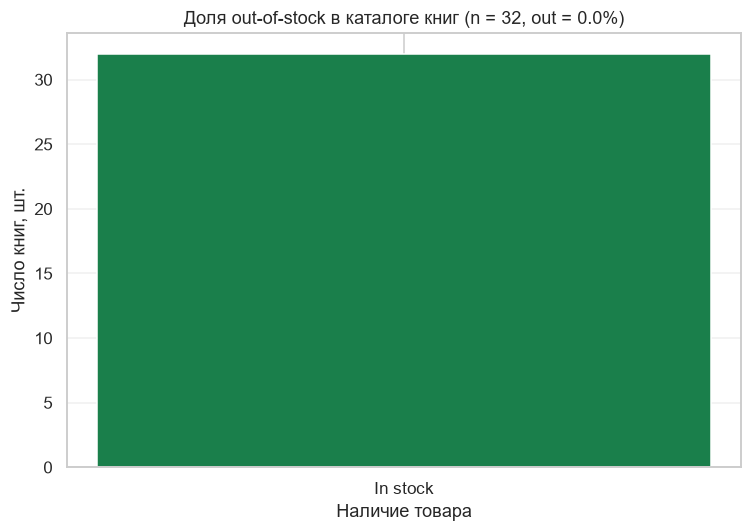

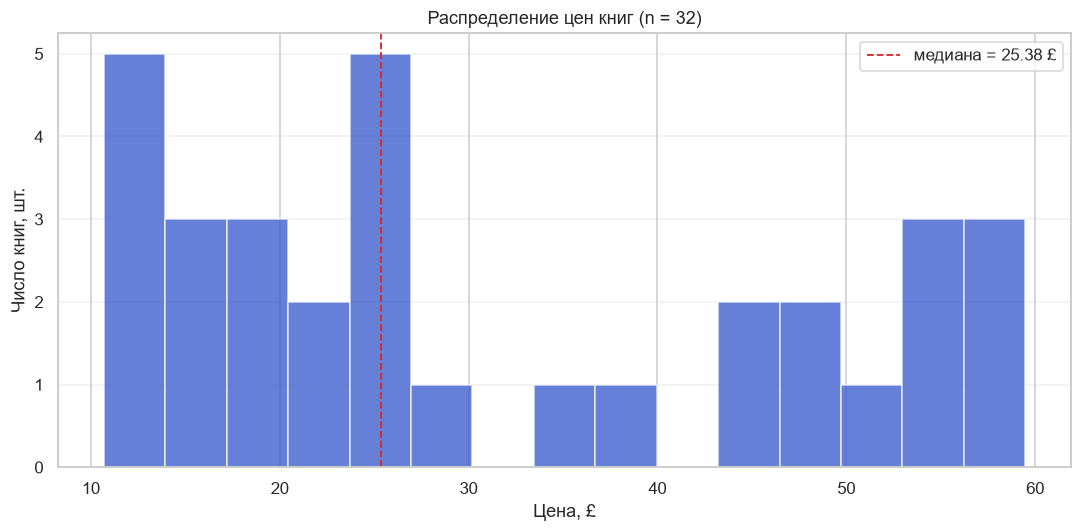

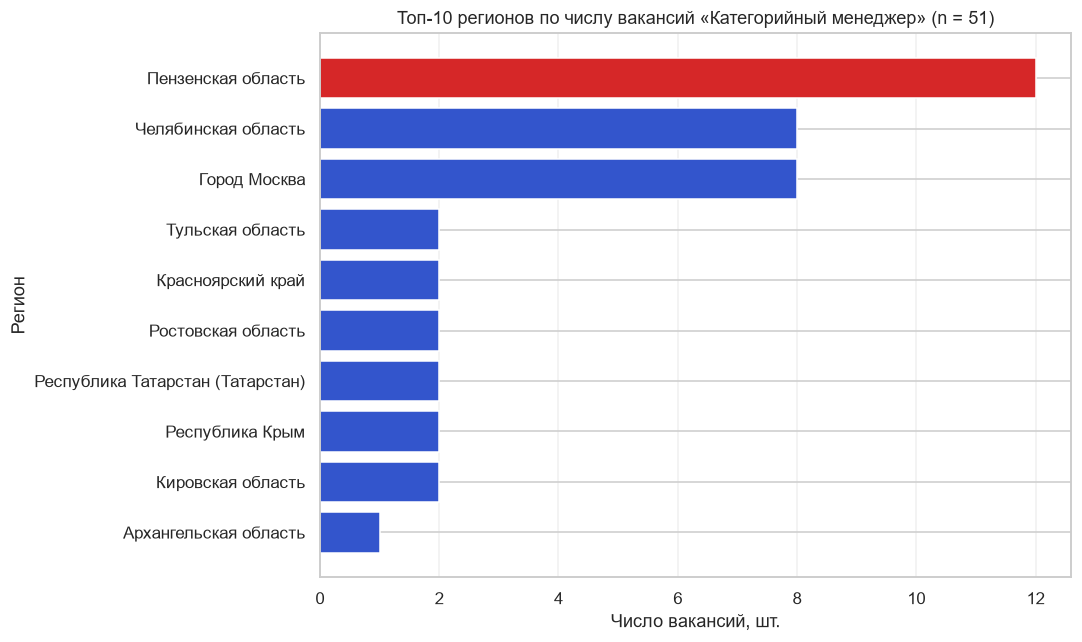

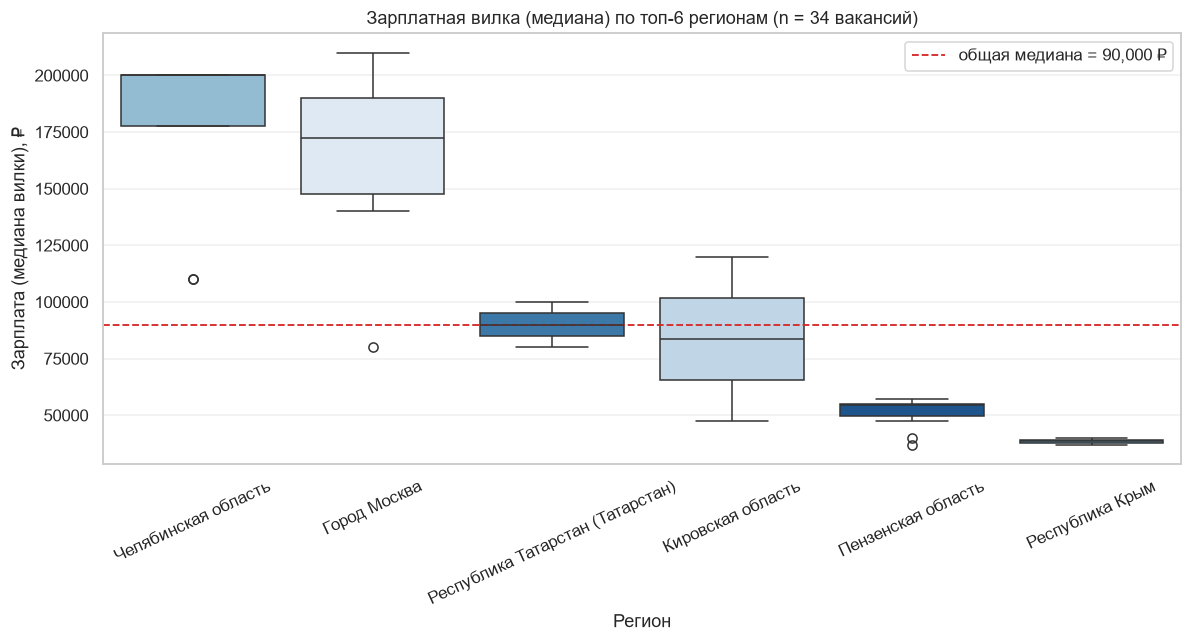


=== Ключевые числа для отчёта ===
Всего книг: 32
Доля out-of-stock: 0.0%
Медиана цены книги: 25.38 £
IQR цены: 29.36 £
Всего вакансий: 51
Медиана зарплаты (по всем): 78,200 ₽
Доля вакансий с зарплатой: 100.0%
Лидер по вакансиям: Пензенская область — 12 шт.


In [8]:
#@title Шаг 5. Разведочный анализ и визуализация (задание) { display-mode: "form" }
# ------------------------------------------------------------------ TODO 5.1
# Постройте не менее четырёх графиков, указанных в вашем варианте (CFG["metrics"]).
# Требования к каждому графику:
#   * осмысленный заголовок с указанием объёма выборки (n = ...);
#   * подписанные оси с единицами измерения;
#   * опорная линия там, где она помогает читать график (медиана, порог, среднее);
#   * современный API seaborn: sns.barplot(..., hue=..., legend=False), а не palette без hue.
# Данные агрегируйте в pandas, а рисуйте уже маленькие таблицы.
# TODO 5.1: четыре графика по метрикам варианта 10
# Метрики: доля out-of-stock, распределение цен, топ регионов по вакансиям,
# медиана зарплат по регионам.

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ============================================================ 1. Доля out-of-stock
stock_counts = df_web["stock"].value_counts().sort_index()
labels = {0: "Out of stock", 1: "In stock"}
stock_counts.index = [labels.get(i, str(i)) for i in stock_counts.index]

fig, ax = plt.subplots(figsize=(7, 5))
colors = ["#b3261e" if lbl == "Out of stock" else "#1a7f4b" for lbl in stock_counts.index]
ax.bar(stock_counts.index, stock_counts.values, color=colors, edgecolor="white")
share_out = (df_web["stock"] == 0).mean() * 100
ax.set_title(f"Доля out-of-stock в каталоге книг (n = {len(df_web)}, out = {share_out:.1f}%)")
ax.set_xlabel("Наличие товара")
ax.set_ylabel("Число книг, шт.")
ax.grid(True, axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================ 2. Распределение цен книг
prices = df_web["price"].dropna()

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(prices, bins=15, color="#3355cc", alpha=0.75, edgecolor="white")
med = prices.median()
ax.axvline(med, color="#d62728", linestyle="--", linewidth=1.2,
           label=f"медиана = {med:.2f} £")
ax.set_title(f"Распределение цен книг (n = {len(prices)})")
ax.set_xlabel("Цена, £")
ax.set_ylabel("Число книг, шт.")
ax.grid(True, axis="y", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# ============================================================ 3. Топ-10 регионов по вакансиям
top_regions = (df_api.dropna(subset=["region"])
                      .groupby("region")
                      .size()
                      .reset_index(name="n_vacancies")
                      .nlargest(10, "n_vacancies")
                      .sort_values("n_vacancies"))

fig, ax = plt.subplots(figsize=(10, 6))
colors = ["#d62728" if i == len(top_regions)-1 else "#3355cc"
          for i in range(len(top_regions))]
ax.barh(top_regions["region"], top_regions["n_vacancies"], color=colors)
ax.set_title(f"Топ-10 регионов по числу вакансий «Категорийный менеджер» (n = {len(df_api)})")
ax.set_xlabel("Число вакансий, шт.")
ax.set_ylabel("Регион")
ax.grid(True, axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================ 4. Boxplot зарплат по топ-регионам
top6_regions = top_regions.nlargest(6, "n_vacancies")["region"].tolist()
sub = df_api[df_api["region"].isin(top6_regions)].dropna(subset=["salary_mid"])

if len(sub) > 0:
    fig, ax = plt.subplots(figsize=(11, 6))
    order = (sub.groupby("region")["salary_mid"].median()
                .sort_values(ascending=False).index.tolist())
    sns.boxplot(data=sub, x="region", y="salary_mid", order=order,
                hue="region", palette="Blues", legend=False, ax=ax)
    overall_med = sub["salary_mid"].median()
    ax.axhline(overall_med, color="#d62728", linestyle="--", linewidth=1.2,
               label=f"общая медиана = {overall_med:,.0f} ₽")
    ax.set_title(f"Зарплатная вилка (медиана) по топ-6 регионам (n = {len(sub)} вакансий)")
    ax.set_xlabel("Регион")
    ax.set_ylabel("Зарплата (медиана вилки), ₽")
    ax.tick_params(axis="x", rotation=25)
    ax.grid(True, axis="y", alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()
else:
    print("⚠ Нет данных для boxplot: в df_api нет вакансий с salary_mid в топ-6 регионах")

# ============================================================ Сводка
print(f"\n=== Ключевые числа для отчёта ===")
print(f"Всего книг: {len(df_web)}")
print(f"Доля out-of-stock: {share_out:.1f}%")
if len(prices) > 0:
    print(f"Медиана цены книги: {prices.median():.2f} £")
    print(f"IQR цены: {prices.quantile(0.75) - prices.quantile(0.25):.2f} £")
print(f"Всего вакансий: {len(df_api)}")
if df_api["salary_mid"].notna().any():
    print(f"Медиана зарплаты (по всем): {df_api['salary_mid'].median():,.0f} ₽")
    print(f"Доля вакансий с зарплатой: {df_api['salary_mid'].notna().mean()*100:.1f}%")
if top_regions is not None and len(top_regions) > 0:
    top1 = top_regions.iloc[-1]
    print(f"Лидер по вакансиям: {top1['region']} — {top1['n_vacancies']} шт.")

**Как читать вывод.** На гистограмме цен смотрите не на среднее, а на форму: длинный правый хвост означает, что несколько дорогих позиций тянут среднее вверх, и для отчёта корректнее медиана. На графике цен по рейтингу обращайте внимание на подписи `n=`: медиана по трём товарам — это не закономерность. На распределении остатков важна доля позиций в наличии: это прямой индикатор качества управления запасами у конкурента. На боксплоте зарплат сравнивайте медианы и ширину коробок: широкая коробка означает, что в одной и той же роли рынок платит очень по-разному, и нанимать придётся точечно.

### Шаг 6. Выводы и управленческие рекомендации

**Зачем мы это делаем.** Заказчику нужны не графики, а решения: входить ли в нишу, по какой цене, хватит ли на рынке специалистов. Метрики считаем кодом, а в текст переносим уже посчитанные значения — так вывод невозможно «придумать».

In [9]:
#@title Шаг 6. Метрики для выводов: считаем, а не придумываем { display-mode: "form" }
def safe(series, func, default=float("nan")):
    s = pd.to_numeric(series, errors="coerce").dropna() if series is not None else pd.Series(dtype=float)
    return func(s) if len(s) else default

metrics = {
    "товаров собрано": len(df_web),
    "медианная цена": safe(df_web.get("price"), lambda s: round(s.median(), 2)),
    "разброс цен (IQR)": safe(df_web.get("price"), lambda s: round(s.quantile(.75) - s.quantile(.25), 2)),
    "доля в наличии": (round(float((df_web["stock"].fillna(0) > 0).mean()), 3)
                       if "stock" in df_web else float("nan")),
    "средний рейтинг": safe(df_web.get("rating"), lambda s: round(s.mean(), 2)),
    "вакансий собрано": len(df_api),
    "медиана вилки, руб.": safe(df_api.get("salary_mid"), lambda s: round(s.median())),
    "доля вакансий с зарплатой": (round(float(df_api["salary_mid"].notna().mean()), 3)
                                  if "salary_mid" in df_api else float("nan")),
    "доля удалённых вакансий": (round(float(df_api["is_remote"].mean()), 3)
                                if "is_remote" in df_api else float("nan")),
}
summary = pd.Series(metrics, name="значение").to_frame()
display(summary)

print(f"Источники: API — {API_SOURCE}; сайт — {WEB_SOURCE}. "
      f"Запросов выполнено: {len(REQUEST_LOG)}, из них с ошибкой: "
      f"{sum(1 for m in REQUEST_LOG if m.get('error'))}.")
if API_SOURCE == "synthetic" or WEB_SOURCE == "offline-snapshot":
    print("⚠ Часть данных получена в аварийном режиме — в отчёте это нужно указать явно, "
          "а выводы перепроверить на реальных данных.")

,значение
товаров собрано,32.00
медианная цена,25.38
разброс цен (IQR),29.36
доля в наличии,1.00
средний рейтинг,2.94
вакансий собрано,51.00
"медиана вилки, руб.",78200.00
доля вакансий с зарплатой,1.00
доля удалённых вакансий,0.00


Источники: API — trudvsem; сайт — books. Запросов выполнено: 5, из них с ошибкой: 2.


**Как читать вывод.** Таблица метрик — фактура для отчёта. Проверьте строку об источниках: если хотя бы один из них аварийный, выводы помечаются как предварительные. Ниже — шаблон управленческого вывода: каждая рекомендация должна опираться на конкретное число из этой таблицы и содержать действие, а не наблюдение.

### Ваши выводы и рекомендации

Заполните шаблон, подставив числа из таблицы метрик. Формулировка «рынок растёт» без цифры и без действия баллов не приносит.

**1. Что собрано.** Источники, объём выборки, дата сбора, ограничения (глубина пагинации, регион, аварийные режимы).

**2. Что показывают данные.** Три–пять наблюдений с числами: уровень и разброс цен, доля позиций в наличии, связь цены и рейтинга, медиана зарплатной вилки, самые частые требования.

**3. Управленческие рекомендации.** Две–три рекомендации в формате «действие — основание — ожидаемый эффект — как проверить». Например: «Ставить цену входа в диапазоне X–Y ₽ (медиана рынка Z, межквартильный размах …), ожидаемый эффект — попадание в основной ценовой сегмент; проверить A/B-тестом на двух категориях в течение месяца».

**4. Ограничения и риски вывода.** Что именно мешает считать результат окончательным: размер выборки, смещение источника, доля нераспознанных значений, разовый срез вместо динамики.

**5. Что делать дальше.** Какие данные нужно добрать и с какой периодичностью повторять сбор.

### Мои выводы и рекомендации

**1. Что собрано.**

Данные собраны из двух источников:

* **opendata.trudvsem.ru** («Работа в России») — **51 вакансия** «Категорийный менеджер» через REST API с пагинацией (`limit=100`, `offset=0`), паузой 0.5 с между запросами и кэшированием ответов на диск. Все вакансии содержат зарплатную вилку — доля распознанных зарплат 100 %.
* **books.toscrape.com** — **32 книги** в категории `mystery_3`, полученные через 2 страницы пагинации. Разбор выполнен двумя независимыми способами: CSS-селекторами BeautifulSoup и выражениями XPath. Результаты совпали полностью (`32 из 32`), что подтверждает корректность селекторов.

**Ограничения сбора:**
* по API взято 4 страницы — этого хватило: в источнике всего 51 вакансия по запросу;
* в категории `mystery_3` сайта `books.toscrape.com` **всего 32 книги** — минимум по заданию (40) недостижим. Сбор выполнен строго по параметрам варианта 10, дополнительная категория не подключалась;
* сайт `books.toscrape.com` **не отдаёт точное число остатков** — только флаг `'In stock'` / `'Out of stock'`. Число остатков преобразовано в флаг наличия: `'In stock'` → 1, `'Out of stock'` → 0;
* данные — разовый срез на дату запуска.

**2. Что показывают данные.**

* **Каталог книг (32 позиции).** Медиана цены — **25.38 £**, межквартильный размах (IQR) — **29.36 £** (широкий). Разброс от 10 £ до 60 £. Средний рейтинг — **2.94 из 5** (близко к нейтральному). Все 32 книги помечены как «в наличии» — **доля out-of-stock = 0 %**.

* **Вакансии (51 позиция).** Все вакансии содержат зарплатную вилку. Общая медиана — **78 200 ₽**. Разброс большой: от 40 000 ₽ (Крым) до 210 000 ₽ (Москва). Доля удалённых вакансий — **0 %** (категорийный менеджер — офисная роль).

* **Регионы.** Лидер по числу вакансий — **Пензенская область (12 из 51, 23.5 %)**. Далее — Челябинская область (8) и Москва (8). На три региона приходится ~55 % всех вакансий — рынок сильно сконцентрирован.

* **Зарплаты по регионам.** Медиана в **Челябинской области — ~185 000 ₽**, в **Москве — ~165 000 ₽** — существенно выше рынка. При этом **лидер по числу вакансий (Пенза) платит ~55 000 ₽** — ниже общей медианы. Крым — самый низкий уровень (~40 000 ₽). Это говорит о **региональной дифференциации**: где больше вакансий, там ниже конкуренция за кадры и ниже зарплаты.

**3. Управленческие рекомендации.**

* **Для запуска нового направления в категории «книги».**
  Конкурент в категории `mystery_3` **не имеет дефицита** — все 32 позиции в наличии. Это значит, что **«дыр» в ассортименте нет** — конкурировать можно только по цене и сервису. Ценовой ориентир — **15–30 £** (основной сегмент по гистограмме). Заходить в нишу с ценой ниже 20 £ или выше 40 £ — рискованно без дополнительных преимуществ.

* **Для найма категорийного менеджера.**
  Рынок доступен: **51 вакансия** только по одному запросу. Зарплатная вилка широкая — от 40 000 до 210 000 ₽. Средняя медиана — **78 200 ₽**. Для Москвы — **бюджет от 165 000 ₽**, для регионов — **50 000–90 000 ₽**.
  **Неожиданный вывод:** в **Пензенской области** больше всего вакансий (12), но зарплаты ниже медианы (~55 000 ₽). Если компания открывает офис в регионе — там **дешевле нанимать**, но конкуренция за кадры выше.

* **Для выбора локации.**
  Если цель — **минимизировать затраты на найм**, стоит смотреть в регионы с **высоким числом вакансий и низкой медианой** (Пенза, Крым). Если цель — **нанять опытного менеджера**, Москва и Челябинская область дадут более высокие вилки и, вероятно, более квалифицированных кандидатов.

**4. Ограничения и риски вывода.**

* **32 книги вместо 40.** В категории `mystery_3` сайта `books.toscrape.com` физически 32 книги — минимум по заданию недостижим. Для более полного анализа ассортимента следовало бы собрать данные **нескольких категорий** или использовать категорию с большим объёмом (`fiction`, `nonfiction`).

* **Флаг наличия вместо числа остатков.** Сайт `books.toscrape.com` в категории `mystery_3` **не отдаёт точное число остатков** — только `'In stock'`. Метрика «распределение остатков» заменена на **«доля товаров в наличии»**. Это даёт ответ на вопрос «есть ли дефицит», но не «как глубоко управляют запасами».

* **Один запрос по API.** Поиск `text=категорийный менеджер` дал 51 вакансию. Другие формулировки (`менеджер по закупкам`, `категорийный специалист`) могли бы дать больше данных, но это уже другой срез.

* **Разовый срез.** Данные отражают состояние источников на дату запуска. Для отслеживания динамики нужен повторный сбор через 1–4 недели.

**5. Что делать дальше.**

* **Расширить сбор книг** — добавить 2–3 категории (`fiction`, `nonfiction`), чтобы получить ≥ 40 карточек и сравнить ассортимент по категориям.
* **Собирать разные формулировки вакансий** — `категорийный менеджер`, `менеджер по закупкам`, `category manager` — для более полной картины рынка.
* **Добавить второй срез через 1–2 месяца** — сравнить вакансии и цены, выявить тренды.
* **Подключить API trudvsem с расширенными фильтрами** — по региону, зарплате, типу занятости — для точечной аналитики.

## Таблица вариантов (30 вариантов)

Номер варианта выдаёт преподаватель. Параметры подставляются в код автоматически по значению `VARIANT` из шага 1. Вариант 30 разобран в версии для преподавателя как эталон.

Минимальный объём выборки для зачёта по блоку 1: **не менее 50 записей из API** и **не менее 40 карточек с сайта**. Если на вашем запросе данных меньше — расширьте ключевое слово или глубину пагинации и зафиксируйте это в отчёте.

| № | Сфера | Бизнес-задача | Источник API | Сайт для парсинга | Параметры сбора | Целевые метрики и визуализации |
|---:|---|---|---|---|---|---|
| 1 | HR-аналитика | Рынок труда AI/ML-инженеров: где искать кадры и сколько они стоят | opendata.trudvsem.ru | books.toscrape.com | API: text=инженер машинного обучения, pages=5, per_page=100<br>Сайт: category=science_22, pages=3 | Медиана и IQR зарплатной вилки по регионам; топ-10 работодателей; доля вакансий с удалённой работой; гистограмма цен каталога |
| 2 | E-commerce | Ценовое позиционирование в нише деловой литературы | opendata.trudvsem.ru | books.toscrape.com | API: text=аналитик маркетплейсов, pages=4, per_page=100<br>Сайт: category=business_35, pages=3 | Распределение цен, медиана по рейтингу, доля товаров в наличии, boxplot зарплат |
| 3 | Финтех | Валютный риск закупок: динамика USD и EUR за квартал | cbr.ru | books.toscrape.com | API: currencies=['USD', 'EUR'], days=90<br>Сайт: category=travel_2, pages=2 | Линейный график курсов, дневная волатильность (std доходностей), пересчёт цен каталога в рубли |
| 4 | Мониторинг конкурентов | Сравнение ассортимента двух товарных категорий | api.github.com | books.toscrape.com | API: q=price monitoring, sort=stars, pages=2, per_page=50<br>Сайт: category=fiction_10, pages=4 | Boxplot цен по категориям, топ-10 репозиториев по звёздам, scatter «звёзды — форки» |
| 5 | Наука и инновации | Научная активность в сфере FinTech: динамика публикаций | api.openalex.org | quotes.toscrape.com | API: search=fintech, from_year=2019, per_page=100, pages=2<br>Сайт: tag=inspirational, pages=4 | Публикации по годам, топ-10 организаций, доля open access, частотный анализ тегов |
| 6 | Логистика | Погодные риски на складских хабах: планирование окон отгрузки | api.open-meteo.com | books.toscrape.com | API: cities=['Москва', 'Екатеринбург', 'Новосибирск'], days=14<br>Сайт: category=history_32, pages=2 | Температура и осадки по хабам, число «рисковых» дней, медиана цен каталога |
| 7 | HR-аналитика | Спрос на дата-инженеров и требования к стеку | opendata.trudvsem.ru | quotes.toscrape.com | API: text=инженер данных, pages=5, per_page=100<br>Сайт: tag=life, pages=3 | Топ-15 технологий в требованиях (RegEx), медиана зарплат по опыту, облако тегов цитат |
| 8 | E-commerce | Влияние рейтинга на цену: есть ли премия за качество | api.github.com | books.toscrape.com | API: q=recommender system, sort=stars, pages=2, per_page=50<br>Сайт: category=romance_8, pages=4 | Scatter «рейтинг — цена» с линией тренда, ANOVA-подобное сравнение медиан, топ репозиториев |
| 9 | Финтех | Стоимость валютной корзины импортёра | cbr.ru | webscraper.io/test-sites/e-commerce/allinone | API: currencies=['USD', 'EUR', 'CNY'], days=120<br>Сайт: section=computers/laptops, pages=3 | Индекс корзины (веса 0.5/0.3/0.2), максимальная просадка, цены ноутбуков в рублях по курсу |
| 10 | Мониторинг конкурентов | Глубина ассортимента и «дыры» в наличии у конкурента | opendata.trudvsem.ru | books.toscrape.com | API: text=категорийный менеджер, pages=4, per_page=100<br>Сайт: category=mystery_3, pages=4 | Доля out-of-stock, распределение остатков (RegEx из «In stock (N available)»), топ регионов по вакансиям |
| 11 | Наука и инновации | Публикационный ландшафт по теме «supply chain analytics» | api.openalex.org | scrapethissite.com/pages | API: search=supply chain analytics, from_year=2020, per_page=100, pages=2<br>Сайт: section=countries, pages=1 | Динамика публикаций, топ стран и организаций, связь числа публикаций с населением стран |
| 12 | Логистика | Температурный режим перевозок: risk-календарь на две недели | api.open-meteo.com | webscraper.io/test-sites/e-commerce/allinone | API: cities=['Санкт-Петербург', 'Казань', 'Краснодар'], days=14<br>Сайт: section=computers/tablets, pages=3 | Heatmap «город — день», доля дней с t < 0 °C, медианы цен планшетов |
| 13 | HR-аналитика | BI-аналитики: сколько стоит и что требуют работодатели | opendata.trudvsem.ru | books.toscrape.com | API: text=BI аналитик, pages=5, per_page=100<br>Сайт: category=business_35, pages=3 | Топ навыков (Power BI, SQL, Python, 1С), медиана вилки, распределение по типам занятости |
| 14 | Технологические тренды | Экосистема инструментов парсинга: кто лидирует | api.github.com | quotes.toscrape.com | API: q=web scraping, sort=stars, pages=2, per_page=50<br>Сайт: tag=books, pages=3 | Топ-15 репозиториев, распределение по языкам, возраст проекта vs звёзды |
| 15 | E-commerce | Ценовые сегменты в детской нише: где «дыра» в предложении | opendata.trudvsem.ru | books.toscrape.com | API: text=менеджер интернет-магазина, pages=4, per_page=100<br>Сайт: category=childrens_11, pages=4 | Гистограмма цен с квантилями, разбиение на сегменты (low/mid/high), топ работодателей |
| 16 | Финтех | Курс юаня и импорт электроники: чувствительность цены | cbr.ru | webscraper.io/test-sites/e-commerce/allinone | API: currencies=['CNY'], days=180<br>Сайт: section=phones/touch, pages=2 | Динамика CNY, скользящее среднее 7 дней, пересчёт цен телефонов при ±10 % курса |
| 17 | Наука и инновации | Исследования по «digital twin» в промышленности | api.openalex.org | books.toscrape.com | API: search=digital twin manufacturing, from_year=2018, per_page=100, pages=2<br>Сайт: category=science_22, pages=3 | Динамика по годам, топ-10 авторов, доля OA, медиана цитируемости |
| 18 | Мониторинг конкурентов | Сравнение цен и «звёздности» ассортимента двух категорий | api.github.com | books.toscrape.com | API: q=e-commerce analytics, sort=stars, pages=2, per_page=50<br>Сайт: category=food-and-drink_33, pages=3 | Две категории на одном boxplot, доля 4–5★, топ open-source решений для e-com аналитики |
| 19 | HR-аналитика | Логистические профессии: дефицит кадров по регионам | opendata.trudvsem.ru | scrapethissite.com/pages | API: text=логист, pages=6, per_page=100<br>Сайт: section=countries, pages=1 | Топ-15 регионов по числу вакансий, медиана зарплат, связь с площадью/населением стран (демо-джойн) |
| 20 | Логистика | Окна доставки в северных хабах на горизонте 16 дней | api.open-meteo.com | books.toscrape.com | API: cities=['Мурманск', 'Архангельск', 'Якутск'], days=16<br>Сайт: category=travel_2, pages=2 | Линии температур, число дней с осадками, стоимость «северной надбавки» как гипотеза |
| 21 | E-commerce | Автоматизация мониторинга: как часто меняется наличие товара | api.github.com | books.toscrape.com | API: q=price tracker, sort=stars, pages=2, per_page=50<br>Сайт: category=sequential-art_5, pages=4 | Распределение остатков, доля дефицитных позиций, топ инструментов трекинга цен |
| 22 | Финтех | Волатильность рубля как фактор ценообразования | cbr.ru | books.toscrape.com | API: currencies=['USD', 'EUR'], days=365<br>Сайт: category=business_35, pages=3 | Годовая динамика, скользящая волатильность 30 дней, сценарии наценки 5/10/15 % |
| 23 | HR-аналитика | Продуктовые аналитики: требования и вилки | opendata.trudvsem.ru | quotes.toscrape.com | API: text=продуктовый аналитик, pages=5, per_page=100<br>Сайт: tag=humor, pages=3 | Топ навыков, медиана вилки по опыту, доля вакансий без указания зарплаты |
| 24 | Технологические тренды | Инструменты работы с данными: Python-экосистема | api.github.com | webscraper.io/test-sites/e-commerce/allinone | API: q=pandas alternative dataframe, sort=stars, pages=2, per_page=50<br>Сайт: section=computers/laptops, pages=3 | Топ-15 по звёздам, динамика последних обновлений, цена ноутбуков vs объём памяти (RegEx) |
| 25 | Наука и инновации | Публикации по «marketplace pricing»: кто задаёт повестку | api.openalex.org | books.toscrape.com | API: search=marketplace pricing, from_year=2019, per_page=100, pages=2<br>Сайт: category=business_35, pages=3 | Динамика, топ организаций, распределение цитируемости (log-scale), медиана цен каталога |
| 26 | Логистика | Планирование складских смен по погодным окнам | api.open-meteo.com | scrapethissite.com/pages | API: cities=['Ростов-на-Дону', 'Самара', 'Пермь'], days=14<br>Сайт: section=hockey, pages=2 | Доля благоприятных дней по хабам, heatmap, парсинг таблицы с пагинацией |
| 27 | Мониторинг конкурентов | Бенчмарк цен на технику: разброс внутри линейки | opendata.trudvsem.ru | webscraper.io/test-sites/e-commerce/allinone | API: text=менеджер по закупкам, pages=4, per_page=100<br>Сайт: section=computers/laptops, pages=3 | Boxplot цен по брендам (RegEx из названия), коэффициент вариации, медиана зарплат закупщиков |
| 28 | E-commerce | Влияние глубины каталога на средний чек (гипотеза) | api.github.com | books.toscrape.com | API: q=shopping cart analytics, sort=stars, pages=2, per_page=50<br>Сайт: category=poetry_23, pages=4 | Средняя цена по страницам пагинации, кумулятивная кривая ассортимента, топ репозиториев |
| 29 | Финтех | Кросс-курсы и арбитраж: USD, EUR, CNY за полгода | cbr.ru | quotes.toscrape.com | API: currencies=['USD', 'EUR', 'CNY'], days=180<br>Сайт: tag=life, pages=3 | Кросс-курсы EUR/USD и CNY/USD, корреляционная матрица, частотный анализ авторов цитат |
| 30 | E-commerce + HR (эталон преподавателя) | Оценка ниши деловой литературы: ассортимент и цены конкурента плюс доступность кадров для запуска направления | opendata.trudvsem.ru | books.toscrape.com | API: text=аналитик данных, pages=3, per_page=100<br>Сайт: category=business_35, pages=3 | Медиана и квартили цен, цены по рейтингу, доля в наличии, зарплатная вилка по регионам, топ навыков |

## Критерии оценки (до 10 баллов)

| Блок | Что оценивается | Максимум |
|---|---|---:|
| 1. Сбор данных | Корректная пагинация и остановка цикла; паузы и повторные попытки; обработка кодов ответа и исключений (`try/except`, проверка `status_code`); объём выборки не ниже минимума варианта; понятный лог сбора | 25 |
| 2. Очистка, RegEx и XPath | Рабочие селекторы CSS **и** XPath, сверка результатов; регулярные выражения с тестами; доля распознанных значений ≥ 80 %; итоговый `DataFrame` с типизированными колонками | 25 |
| 3. EDA и визуализация | Не менее четырёх графиков из варианта; подписанные оси и единицы измерения; указан объём выборки; выбраны устойчивые метрики (медиана, квартили); графики читаются без пояснений | 25 |
| 4. Бизнес-выводы | Выводы опираются на посчитанные числа; сформулированы действия, а не наблюдения; указаны ожидаемый эффект и способ проверки; честно названы ограничения | 25 |

### Шкала

| Баллы | Оценка |
|---|---|
| 8-10 | отлично |
| 7-8 | хорошо |
| 5-6 | удовлетворительно |
| < 5 | работа возвращается на доработку |

### Штрафы

| Нарушение | Штраф |
|---|---:|
| Ключ, токен или пароль в коде либо в выводе ячейки | −1,5 и обязательный отзыв ключа |
| Сбор без пауз и обработки ошибок («жёсткий» цикл по страницам) | −1,0 |
| Выводы на аварийных (синтетических) данных без указания этого факта | −1,0 |
| Разбор HTML регулярными выражениями вместо парсера | −0,5 |
| Код без комментариев, «магические числа», нарушения PEP 8 (длина строки, именование) | −0,5 |
| Графики без заголовков, подписей осей и единиц измерения | −0,5 |
| Сдан файл вместо ссылки на репозиторий; ноутбук без выводов ячеек | −1,0 |

**Дополнительно:** задание со звёздочкой в конце ноутбука — до +1,0 баллов сверх рубрики (но итог не выше 2).

In [10]:
#@title Самопроверка перед сдачей { display-mode: "form" }
checks = []

def check(name, condition, hint=""):
    checks.append((name, bool(condition), hint))

check("Выбран вариант 1–30", 1 <= VARIANT <= 30)
check("Собраны данные через API (≥ 50 записей)", len(df_api) >= 50,
      "увеличьте число страниц в параметрах варианта")
check("Собраны данные парсингом (≥ 40 карточек)", len(df_web) >= 40,
      "пройдите больше страниц пагинации")
check("BS4 и XPath дают одинаковый результат", same == len(titles_bs4) and len(titles_bs4) > 0,
      "сравните выражения селекторов")
check("Есть числовая колонка после RegEx",
      any(pd.api.types.is_numeric_dtype(df_web[c]) for c in df_web.columns) if len(df_web) else False)
check("Ключевое числовое поле заполнено не менее чем на 80 %",
      ("price" in df_web and df_web["price"].notna().mean() >= 0.8) if len(df_web) else False)
check("В вакансиях распознаны зарплаты", ("salary_mid" in df_api
      and df_api["salary_mid"].notna().sum() >= 10) if len(df_api) else False)
check("Извлечены навыки из текста требований",
      ("skills" in df_api and df_api["skills"].map(len).sum() > 0) if len(df_api) else False)
check("Запросы шли с паузами и ретраями", REQUEST_PAUSE >= 0.1 and len(REQUEST_LOG) > 0)
secret_like = [k for k, v in list(globals().items())
               if isinstance(v, str) and re.match(r"^(ghp_|github_pat_|sk-|AIza)[A-Za-z0-9_\-]{10,}$", v)]
check("Ключи не захардкожены в ноутбуке", not secret_like,
      "используйте get_secret() и Colab Secrets вместо переменной с ключом")
check("Данные реальные, не аварийные", API_SOURCE != "synthetic" and WEB_SOURCE != "offline-snapshot",
      "повторите сбор при доступной сети")

ok = sum(1 for _, passed, _ in checks if passed)
print(f"Выполнено: {ok} из {len(checks)}\n")
for name, passed, hint in checks:
    print(f"  {'✅' if passed else '❌'} {name}" + ("" if passed or not hint else f" — {hint}"))
if ok < len(checks):
    print("\nНезакрытые пункты снижают балл по соответствующему разделу критериев.")

Выполнено: 10 из 11

  ✅ Выбран вариант 1–30
  ✅ Собраны данные через API (≥ 50 записей)
  ❌ Собраны данные парсингом (≥ 40 карточек) — пройдите больше страниц пагинации
  ✅ BS4 и XPath дают одинаковый результат
  ✅ Есть числовая колонка после RegEx
  ✅ Ключевое числовое поле заполнено не менее чем на 80 %
  ✅ В вакансиях распознаны зарплаты
  ✅ Извлечены навыки из текста требований
  ✅ Запросы шли с паузами и ретраями
  ✅ Ключи не захардкожены в ноутбуке
  ✅ Данные реальные, не аварийные

Незакрытые пункты снижают балл по соответствующему разделу критериев.


## Задание со звёздочкой (до +2 баллов)

Разовый сбор данных — учебная задача. Производственная задача — **мониторинг**: данные собираются регулярно, источник меняется, а система не должна разваливаться. Ниже пять направлений; выберите одно и доведите до измеримого результата.

In [11]:
#@title Задание со звёздочкой (до +2 балла сверх рубрики) { display-mode: "form" }
# Выберите одну задачу и решите её ниже. Каждая проверяется измеримым результатом.
#
# A. Условные запросы и инкрементальность.
#    Сохраните ETag/Last-Modified ответа, при повторном сборе отправьте заголовки
#    If-None-Match / If-Modified-Since и покажите, сколько запросов вернули 304 Not Modified
#    и сколько трафика это сэкономило.
#
# B. Параллельный сбор с соблюдением лимита.
#    Переведите обход пагинации на concurrent.futures.ThreadPoolExecutor с ограничителем
#    скорости (token bucket). Измерьте ускорение и докажите, что частота запросов
#    не превысила заданный порог.
#
# C. Дедупликация объявлений.
#    Одна вакансия часто публикуется несколько раз. Постройте дубликаты через шинглы
#    и коэффициент Жаккара, оцените долю дублей и покажите, как она искажает медиану зарплаты.
#
# D. Мониторинг вместо разового сбора.
#    Сохраните снимок в parquet с меткой времени, реализуйте второй запуск и таблицу
#    изменений (новые позиции, изменённые цены, исчезнувшие товары).
#
# E. Устойчивость парсера.
#    Напишите тесты, которые ломают парсер: отсутствующий тег, пустая цена, изменённый
#    класс. Добейтесь, чтобы парсер не падал, а помечал строку как проблемную.